In [31]:
import matplotlib.pyplot as plt

plt.style.use('default')

## Procesamiento de Sextans A por chips

Las imágenes de Sextans A se encuentran previamente reducidas y combinadas en una única imagen mosaico. Para realizar el nuevo análisis fotométrico, la imagen se dividió geométricamente en las ocho regiones correspondientes a los ocho chips del detector.

La imagen completa presenta dimensiones:

$$
N_x = 8271\ \mathrm{pix}
$$

$$
N_y = 8387\ \mathrm{pix}
$$

La geometría identificada corresponde a **4 filas y 2 columnas**, obteniéndose un total de ocho regiones.

Las dimensiones resultantes son:

- **Chip 1:** \(2097 \times 4136\) píxeles.
- **Chip 2:** \(2097 \times 4135\) píxeles.
- **Chip 3:** \(2097 \times 4136\) píxeles.
- **Chip 4:** \(2097 \times 4135\) píxeles.
- **Chip 5:** \(2097 \times 4136\) píxeles.
- **Chip 6:** \(2097 \times 4135\) píxeles.
- **Chip 7:** \(2096 \times 4136\) píxeles.
- **Chip 8:** \(2096 \times 4135\) píxeles.

Las pequeñas diferencias de un píxel se deben a que las dimensiones totales de la imagen mosaico no son divisibles exactamente entre cuatro filas y dos columnas.

Por el momento se trabajará únicamente con los filtros **B, V e I**, debido a que los archivos correspondientes a los filtros **R y Hα presentan problemas de truncamiento**.

El procesamiento fotométrico se realizará de manera independiente para cada chip, determinando para cada región sus propios parámetros de FWHM, ruido del cielo, umbral de detección, radio de apertura y anillo de cielo.

### Identificación de píxeles no válidos

La imagen mosaico contiene regiones con valores de \(50000\) ADU. Estos píxeles corresponden a zonas de relleno generadas durante la construcción de la imagen mosaico y no representan señal astronómica válida.

Para el **chip 1 del filtro V** se encontraron:

$$
N_{50000}=236976
$$

píxeles con este valor, equivalentes aproximadamente al:

$$
2.7323\%
$$

del área total del chip.

El encabezado de la imagen establece un nivel de saturación de:

$$
\mathrm{SATURATE}=39000\ \mathrm{ADU}
$$

Por lo tanto, los píxeles con valor \(50000\) ADU se encuentran por encima del nivel válido de la imagen y deberán excluirse del análisis fotométrico.

Durante la selección manual de estrellas y regiones de cielo también se evitarán las zonas afectadas por estos valores.

## Filtro V · Chip 1

### Determinación del FWHM

El primer parámetro determinado para el chip 1 del filtro V fue el ancho a media altura de las fuentes puntuales, \(FWHM\).

Las estrellas fueron inspeccionadas utilizando la tarea `imexamine` de IRAF. Para cada fuente se utilizó el valor de FWHM correspondiente a la medición **DIRECT** reportada por la tarea.

Para obtener una estimación representativa del perfil estelar se seleccionaron preferentemente estrellas:

1. Aisladas.
2. No saturadas.
3. Alejadas de los bordes de la imagen.
4. Alejadas de regiones con valores de \(50000\) ADU.
5. Con perfiles radiales regulares y compatibles con fuentes puntuales.

El nivel de saturación utilizado fue:

$$
I_{\mathrm{sat}}=39000\ \mathrm{ADU}
$$

Por esta razón se descartaron las mediciones correspondientes a estrellas cuyo valor máximo superaba este límite.

También se descartaron fuentes con perfiles anormalmente anchos o poco definidos.

Durante la inspección se identificaron dos mediciones prácticamente idénticas correspondientes a la misma fuente. Para evitar asignarle un peso doble en el cálculo estadístico, únicamente se conservó una de ellas.

In [32]:
import numpy as np
import pandas as pd

# Mediciones obtenidas con IRAF/imexamine para V - chip 1
# FWHM corresponde a la columna DIRECT.

datos = pd.DataFrame({
    "medicion": np.arange(1, 16),
    "peak": [
        52588, 52716, 113.5, 52280, 52653,
        7328, 12195, 742.6, 8914, 6995,
        6987, 6159, 4862, 686.9, 6396
    ],
    "fwhm_direct": [
        10.58, 6.52, 9.10, 5.34, 5.30,
        4.56, 4.52, 4.56, 4.50, 4.34,
        4.34, 4.52, 4.46, 6.06, 4.46
    ]
})

datos

,medicion,peak,fwhm_direct
0,1,52588.0,10.58
1,2,52716.0,6.52
2,3,113.5,9.10
3,4,52280.0,5.34
4,5,52653.0,5.30
5,6,7328.0,4.56
6,7,12195.0,4.52
7,8,742.6,4.56
8,9,8914.0,4.50
9,10,6995.0,4.34


### Selección de las estrellas utilizadas para calcular el FWHM

A partir de las 15 mediciones iniciales se aplicaron los siguientes criterios de selección:

- Las mediciones **1, 2, 4 y 5** fueron descartadas porque presentan valores máximos superiores a \(39000\) ADU y, por tanto, corresponden a estrellas saturadas.
- Las mediciones **3 y 14** fueron descartadas debido a que presentan perfiles considerablemente más anchos que el grupo principal de estrellas.
- La medición **11** fue descartada porque corresponde a una repetición de la misma fuente utilizada en la medición 10.

Las mediciones finalmente utilizadas fueron:

$$
6,\ 7,\ 8,\ 9,\ 10,\ 12,\ 13,\ 15
$$

Los valores de FWHM seleccionados fueron:

$$
4.56,\ 4.52,\ 4.56,\ 4.50,\ 4.34,\ 4.52,\ 4.46,\ 4.46
$$

píxeles.

In [33]:
# Selección manual de estrellas adecuadas para estimar el FWHM.
#
# Se rechazan:
# 1, 2, 4 y 5 -> saturadas (peak > 39000 ADU)
# 3 y 14      -> perfiles anormalmente anchos / fuente poco adecuada
# 11          -> repetición de la misma fuente de la medición 10
#
# Se conservan:
# 6, 7, 8, 9, 10, 12, 13 y 15

seleccion = [6, 7, 8, 9, 10, 12, 13, 15]

fwhm_seleccionado = datos.loc[
    datos["medicion"].isin(seleccion),
    "fwhm_direct"
].to_numpy()

fwhm_mediana = np.median(fwhm_seleccionado)
fwhm_media = np.mean(fwhm_seleccionado)
fwhm_std = np.std(fwhm_seleccionado, ddof=1)

print("Valores seleccionados:")
print(fwhm_seleccionado)

print(f"\nNúmero de estrellas: {len(fwhm_seleccionado)}")
print(f"FWHM mediana = {fwhm_mediana:.3f} pix")
print(f"FWHM medio   = {fwhm_media:.3f} pix")
print(f"Desv. estándar = {fwhm_std:.3f} pix")

Valores seleccionados:
[4.56 4.52 4.56 4.5  4.34 4.52 4.46 4.46]

Número de estrellas: 8
FWHM mediana = 4.510 pix
FWHM medio   = 4.490 pix
Desv. estándar = 0.072 pix


### Estimación del cielo para V · Chip 1

Después de determinar el FWHM característico de las fuentes puntuales, se realizó una estimación del nivel y de la dispersión del cielo para el chip 1 del filtro V.

Las mediciones se realizaron utilizando la tarea `imexamine` de IRAF sobre regiones visualmente libres de fuentes astronómicas. Cada medición corresponde a una región de:

$$
15\times15=225\ \mathrm{pixeles}
$$

Se seleccionaron regiones distribuidas espacialmente sobre el chip y alejadas de estrellas, bordes y zonas con valores de \(50000\) ADU.

Para cada región, `imexamine` proporciona la media, la mediana y la desviación estándar de los valores de los píxeles. Para caracterizar el ruido del cielo se utilizó la desviación estándar:

$$
\sigma_{\mathrm{sky}}
$$

Se realizaron 16 mediciones independientes.

In [34]:
import numpy as np
import pandas as pd

datos_sky_v_chip1 = pd.DataFrame({
    "medicion": np.arange(1, 17),

    "media": [
        -2.753, -2.315, -2.108, -2.299,
        -2.818, -1.401, -1.992, -2.622,
        -2.924, -2.467, -2.070, -2.573,
        -2.299, -2.544, -1.407, -2.642
    ],

    "mediana": [
        -2.816, -2.133, -1.931, -2.232,
        -2.782, -1.397, -1.892, -1.920,
        -3.044, -2.681, -2.130, -2.489,
        -2.249, -2.625, -1.471, -2.525
    ],

    "sigma": [
        6.735, 2.786, 3.190, 3.229,
        2.864, 3.003, 4.485, 7.598,
        3.587, 3.223, 2.950, 3.278,
        2.990, 3.127, 3.014, 3.670
    ]
})

datos_sky_v_chip1

,medicion,media,mediana,sigma
0,1,-2.753,-2.816,6.735
1,2,-2.315,-2.133,2.786
2,3,-2.108,-1.931,3.190
3,4,-2.299,-2.232,3.229
4,5,-2.818,-2.782,2.864
5,6,-1.401,-1.397,3.003
6,7,-1.992,-1.892,4.485
7,8,-2.622,-1.920,7.598
8,9,-2.924,-3.044,3.587
9,10,-2.467,-2.681,3.223


### Selección robusta de las regiones de cielo

Algunas regiones pueden contener contaminación residual producida por estrellas débiles, estructuras del fondo o fuentes no identificadas visualmente. Por esta razón, se utilizó un criterio robusto basado en el rango intercuartílico de la distribución de \(\sigma\).

Se calcularon:

$$
Q_1
$$

y

$$
Q_3
$$

y se definió:

$$
IQR=Q_3-Q_1
$$

El límite superior de Tukey se estableció como:

$$
\sigma_{\mathrm{lim}}=Q_3+1.5\,IQR
$$

Las regiones con:

$$
\sigma>\sigma_{\mathrm{lim}}
$$

fueron consideradas atípicas y se excluyeron de la estimación final del ruido del cielo.

In [35]:
sigma = datos_sky_v_chip1["sigma"].to_numpy()

Q1 = np.percentile(sigma, 25)
Q3 = np.percentile(sigma, 75)
IQR = Q3 - Q1

limite_superior = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:.4f} ADU")
print(f"Q3 = {Q3:.4f} ADU")
print(f"IQR = {IQR:.4f} ADU")
print(f"Límite superior de Tukey = {limite_superior:.4f} ADU")

Q1 = 2.9998 ADU
Q3 = 3.6078 ADU
IQR = 0.6080 ADU
Límite superior de Tukey = 4.5198 ADU


In [36]:
mask_sky = datos_sky_v_chip1["sigma"] <= limite_superior

sky_aceptado = datos_sky_v_chip1[mask_sky]
sky_rechazado = datos_sky_v_chip1[~mask_sky]

sigma_sky = np.median(sky_aceptado["sigma"])
sky_mediana = np.median(datos_sky_v_chip1["mediana"])

print("Regiones aceptadas:", len(sky_aceptado))
print("Regiones rechazadas:", len(sky_rechazado))

print()
print("Mediciones rechazadas:")
print(sky_rechazado[["medicion", "sigma"]])

print()
print(f"Sigma del cielo adoptado = {sigma_sky:.4f} ADU")
print(f"Mediana del nivel de cielo = {sky_mediana:.4f} ADU")

Regiones aceptadas: 14
Regiones rechazadas: 2

Mediciones rechazadas:
   medicion  sigma
0         1  6.735
7         8  7.598

Sigma del cielo adoptado = 3.1585 ADU
Mediana del nivel de cielo = -2.2405 ADU


**### Visualización de la selección de regiones de cielo**

La siguiente gráfica muestra la dispersión medida en cada región de cielo y el límite superior de Tukey utilizado para identificar mediciones atípicas. Las regiones por encima del límite fueron excluidas antes de adoptar el valor representativo de \(\sigma_{\mathrm{sky}}\).


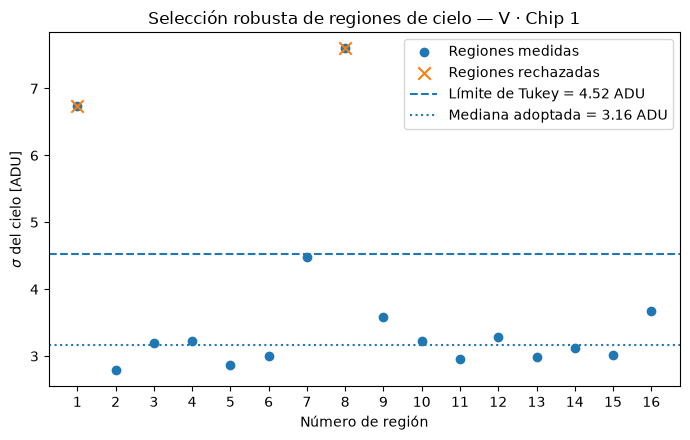

In [37]:
plt.figure(figsize=(7, 4.5))

plt.scatter(
    datos_sky_v_chip1["medicion"],
    datos_sky_v_chip1["sigma"],
    label="Regiones medidas"
)

plt.scatter(
    sky_rechazado["medicion"],
    sky_rechazado["sigma"],
    marker="x",
    s=80,
    label="Regiones rechazadas"
)

plt.axhline(
    limite_superior,
    linestyle="--",
    label=f"Límite de Tukey = {limite_superior:.2f} ADU"
)

plt.axhline(
    sigma_sky,
    linestyle=":",
    label=f"Mediana adoptada = {sigma_sky:.2f} ADU"
)

plt.xlabel("Número de región")
plt.ylabel(r"$\sigma$ del cielo [ADU]")
plt.title("Selección robusta de regiones de cielo — V · Chip 1")
plt.xticks(datos_sky_v_chip1["medicion"])
plt.legend()
plt.tight_layout()
plt.show()


### Resultado del cielo para V · Chip 1

De las 16 regiones de cielo inicialmente medidas, dos presentaron valores de dispersión superiores al límite robusto definido mediante el criterio de Tukey.

El límite obtenido fue:

$$
\sigma_{\mathrm{lim}}\approx4.52\ \mathrm{ADU}
$$

Las dos regiones rechazadas presentaron:

$$
\sigma=6.735\ \mathrm{ADU}
$$

y

$$
\sigma=7.598\ \mathrm{ADU}
$$

Después de excluir estas regiones, la mediana de las dispersiones de las 14 regiones aceptadas fue:

$$
\boxed{\sigma_{\mathrm{sky},V,\mathrm{chip1}}=3.16\ \mathrm{ADU}}
$$

La mediana del nivel de fondo medida sobre las regiones analizadas fue aproximadamente:

$$
\boxed{\mathrm{sky}_{\mathrm{med}}\approx-2.24\ \mathrm{ADU}}
$$

Este valor de $(\sigma_{\mathrm{sky}})$ será utilizado como parámetro de ruido para las pruebas de detección de fuentes con `DAOFIND`.

### Determinación del umbral de detección para V · Chip 1

Una vez determinados el FWHM y la dispersión del cielo, se procedió a evaluar diferentes valores del parámetro `threshold` de `DAOFIND`.

Para el chip 1 del filtro V se adoptaron inicialmente:

$$
\mathrm{FWHM}=4.51\ \mathrm{pix}
$$

y

$$
\sigma_{\mathrm{sky}}=3.16\ \mathrm{ADU}
$$

En `DAOFIND`, el parámetro `threshold` representa el nivel mínimo de detección expresado en unidades de la dispersión del fondo.

Por lo tanto, una fuente debe superar aproximadamente:

$$
I_{\mathrm{det}}=\mathrm{threshold}\times\sigma_{\mathrm{sky}}
$$

sobre el nivel local del cielo para ser considerada como una detección candidata.

Se evaluarán diferentes valores de `threshold` con el objetivo de estudiar la variación del número de fuentes detectadas y seleccionar posteriormente un valor adecuado para el procesamiento fotométrico.

### Evaluación del número de detecciones en función del threshold

Se realizaron pruebas de detección con `DAOFIND` utilizando diferentes valores del parámetro `threshold`.

Para todas las pruebas se mantuvieron constantes:

$$
\mathrm{FWHM}=4.51\ \mathrm{pix}
$$

y

$$
\sigma_{\mathrm{sky}}=3.16\ \mathrm{ADU}
$$

Los valores de `threshold` evaluados fueron:

$$
2.0,\ 2.5,\ 3.0,\ 3.5,\ 4.0,\ 5.0,\ 6.0
$$

El número de detecciones disminuye a medida que aumenta el umbral, debido a que se exige una señal progresivamente mayor respecto a la dispersión del fondo para aceptar una fuente candidata.

In [38]:
import numpy as np
import pandas as pd

thresholds = np.array([
    2.0,
    2.5,
    3.0,
    3.5,
    4.0,
    5.0,
    6.0
])

detecciones = np.array([
    70760,
    38056,
    20442,
    12362,
    8138,
    3609,
    1536
])

tabla_threshold_v_chip1 = pd.DataFrame({
    "threshold": thresholds,
    "detecciones": detecciones
})

tabla_threshold_v_chip1

,threshold,detecciones
0,2.0,70760
1,2.5,38056
2,3.0,20442
3,3.5,12362
4,4.0,8138
5,5.0,3609
6,6.0,1536


### Ajuste de \(\ln N\) en función del threshold

Para analizar de manera cuantitativa la disminución del número de detecciones se estudió:

$$
\ln N
$$

como función del threshold.

Se ajustó un polinomio de segundo grado:

$$
\ln N = ax^2+bx+c
$$

donde \(x\) representa el valor del `threshold`.

El objetivo es identificar una región de transición en la curva entre el rápido descenso de detecciones a umbrales bajos y el comportamiento más estable observado para umbrales mayores.

Como criterio operacional se determina el punto donde la pendiente del ajuste satisface:

$$
\frac{d\ln N}{dx}=-1
$$

In [39]:
import numpy as np
import matplotlib.pyplot as plt

lnN = np.log(detecciones)

coef = np.polyfit(thresholds, lnN, 2)

a, b, c = coef

ajuste = np.polyval(coef, thresholds)

# Coeficiente de determinación R^2
ss_res = np.sum((lnN - ajuste)**2)
ss_tot = np.sum((lnN - np.mean(lnN))**2)

r2 = 1 - ss_res / ss_tot

print(f"a = {a:.8f}")
print(f"b = {b:.8f}")
print(f"c = {c:.8f}")
print(f"R² = {r2:.8f}")

a = 0.06863050
b = -1.48709036
c = 13.83027928
R² = 0.99850273


In [40]:
# Para:
# ln(N) = a*x^2 + b*x + c
#
# la derivada es:
# d ln(N)/dx = 2*a*x + b
#
# Buscamos el punto donde la pendiente sea -1.

threshold_optimo = (-1 - b) / (2 * a)

print(f"Threshold calculado = {threshold_optimo:.4f}")

Threshold calculado = 3.5486


**### Visualización del comportamiento de `DAOFIND`**

Las siguientes gráficas permiten observar cómo disminuye el número de detecciones al incrementar el `threshold` y cómo se determina el valor adoptado a partir del ajuste de \(\ln N\).


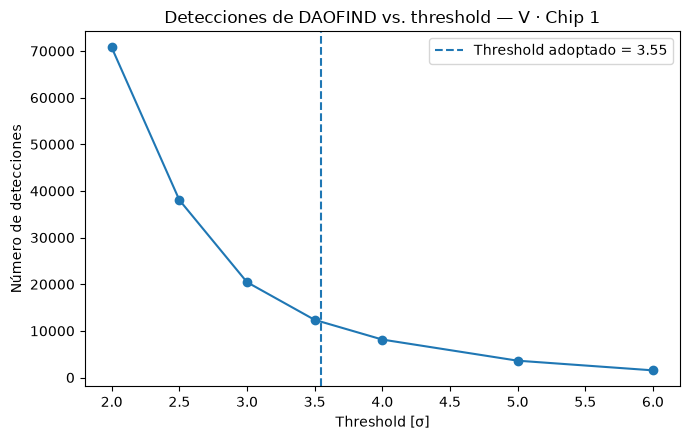

In [41]:
plt.figure(figsize=(7, 4.5))

plt.plot(
    thresholds,
    detecciones,
    marker="o"
)

plt.axvline(
    threshold_optimo,
    linestyle="--",
    label=f"Threshold adoptado = {threshold_optimo:.2f}"
)

plt.xlabel("Threshold [σ]")
plt.ylabel("Número de detecciones")
plt.title("Detecciones de DAOFIND vs. threshold — V · Chip 1")
plt.legend()
plt.tight_layout()
plt.show()


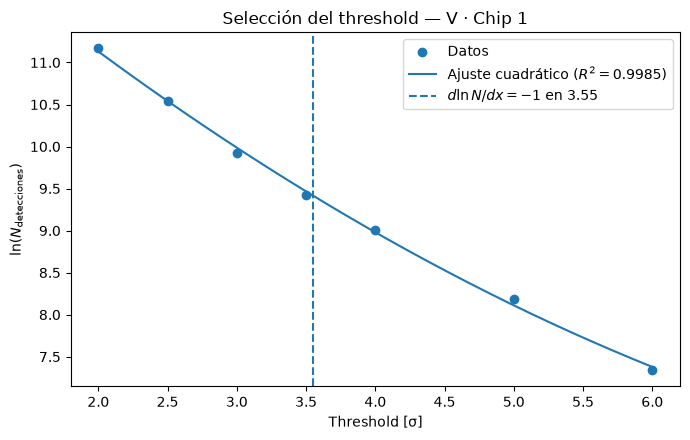

In [42]:
x_fit = np.linspace(
    thresholds.min(),
    thresholds.max(),
    300
)

lnN_fit = np.polyval(
    coef,
    x_fit
)

plt.figure(figsize=(7, 4.5))

plt.scatter(
    thresholds,
    lnN,
    label="Datos"
)

plt.plot(
    x_fit,
    lnN_fit,
    label=rf"Ajuste cuadrático ($R^2={r2:.4f}$)"
)

plt.axvline(
    threshold_optimo,
    linestyle="--",
    label=rf"$d\ln N/dx=-1$ en {threshold_optimo:.2f}"
)

plt.xlabel("Threshold [σ]")
plt.ylabel(r"$\ln(N_{\mathrm{detecciones}})$")
plt.title("Selección del threshold — V · Chip 1")
plt.legend()
plt.tight_layout()
plt.show()


### Threshold adoptado para V · Chip 1

El ajuste obtenido fue:

$$
\ln N =
0.0686305x^2
-1.4870904x
+13.8302793
$$

con un coeficiente de determinación:

$$
R^2=0.9985
$$

La derivada del ajuste es:

$$
\frac{d\ln N}{dx}
=
0.137261x-1.4870904
$$

Aplicando el criterio:

$$
\frac{d\ln N}{dx}=-1
$$

se obtiene:

$$
x\approx3.5486
$$

Por lo tanto, se adopta para el chip 1 del filtro V:

$$
\boxed{\mathrm{threshold}_{V,\mathrm{chip1}}=3.55}
$$

Este valor será utilizado para generar el catálogo inicial de detecciones con `DAOFIND`.

### Catálogo inicial de detecciones para V · Chip 1

A partir del umbral obtenido mediante el análisis de la variación del número de detecciones se adoptó:

$$
\mathrm{threshold}_{V,\mathrm{chip1}}=3.55
$$

Con este valor se ejecutó nuevamente `DAOFIND`, obteniéndose:

$$
\boxed{N_{\mathrm{DAOFIND}}=11819}
$$

detecciones iniciales.

Este catálogo todavía puede contener fuentes localizadas cerca de los bordes de la imagen o próximas a píxeles no válidos con valor \(50000\) ADU.

Antes de realizar la fotometría de apertura se aplicará un filtro geométrico para garantizar que la apertura fotométrica no intersecte estas regiones.

El radio de apertura provisional es:

$$
r_{\mathrm{ap}}=3\,\mathrm{FWHM}
$$

$$
r_{\mathrm{ap}}=3(4.51)=13.53\ \mathrm{pix}
$$

Por lo tanto, inicialmente se exigirá que cada fuente se encuentre a una distancia superior a \(13.53\) píxeles tanto de los píxeles no válidos como de los bordes del chip.

In [43]:
from pathlib import Path
from astropy.io import fits
from scipy.ndimage import distance_transform_edt
import numpy as np
import pandas as pd

# Ruta de trabajo
base = (
    Path.home()
    / "Desktop"
    / "Universidad"
    / "tesis"
    / "dataSextansA"
)

imagen_path = base / "chips/chip1/SexA_V_chip1.fits"
catalogo_path = base / "chips/chip1/V_chip1_thr3_55.coo"

# Parámetros ya determinados
fwhm = 4.51
r_ap = 3 * fwhm

print(f"FWHM = {fwhm:.2f} pix")
print(f"Radio de apertura = {r_ap:.2f} pix")

FWHM = 4.51 pix
Radio de apertura = 13.53 pix


In [44]:
# Leer imagen
imagen = fits.getdata(imagen_path).astype(float)

ny, nx = imagen.shape

# Píxeles no válidos del mosaico
mask_invalidos = (imagen == 50000)

# Distancia de cada píxel válido al píxel inválido más cercano
dist_invalidos = distance_transform_edt(~mask_invalidos)

print("Dimensiones:", imagen.shape)
print("Píxeles = 50000:", mask_invalidos.sum())
print(
    "Porcentaje inválido:",
    100 * mask_invalidos.sum() / imagen.size
)

Dimensiones: (2097, 4136)
Píxeles = 50000: 236976
Porcentaje inválido: 2.73228126392221


In [45]:
columnas = [
    "x",
    "y",
    "mag_daofind",
    "sharpness",
    "sround",
    "ground",
    "id"
]

catalogo = pd.read_csv(
    catalogo_path,
    comment="#",
    sep=r"\s+",
    names=columnas,
    engine="python"
)

print("Detecciones leídas:", len(catalogo))

catalogo.head()

Detecciones leídas: 11819


,x,y,mag_daofind,sharpness,sround,ground,id
0,4027.759,13.291,-0.998,0.353,-0.918,-1.154,1
1,4086.174,12.138,-0.764,0.341,0.416,0.411,2
2,4125.897,14.336,-0.582,0.568,0.130,-0.565,3
3,4021.278,12.859,-0.682,0.609,0.080,0.674,4
4,4024.592,13.334,-0.514,0.246,0.010,0.489,5


In [46]:
# DAOFIND utiliza coordenadas 1-based.
# Las convertimos temporalmente a índices 0-based de NumPy.

xpix = np.rint(catalogo["x"].to_numpy()).astype(int) - 1
ypix = np.rint(catalogo["y"].to_numpy()).astype(int) - 1

# Asegurar índices válidos
dentro = (
    (xpix >= 0) &
    (xpix < nx) &
    (ypix >= 0) &
    (ypix < ny)
)

# Distancia al píxel 50000 más cercano
d_invalidos = np.zeros(len(catalogo))
d_invalidos[:] = np.nan

d_invalidos[dentro] = dist_invalidos[
    ypix[dentro],
    xpix[dentro]
]

# Distancia geométrica al borde de la imagen
x = catalogo["x"].to_numpy()
y = catalogo["y"].to_numpy()

d_borde = np.minimum.reduce([
    x - 1,
    nx - x,
    y - 1,
    ny - y
])

catalogo["dist_invalidos"] = d_invalidos
catalogo["dist_borde"] = d_borde

# La apertura completa debe caber en una región válida
mask_limpio = (
    dentro &
    (catalogo["dist_invalidos"] > r_ap) &
    (catalogo["dist_borde"] > r_ap)
)

catalogo_limpio = catalogo[mask_limpio].copy()
catalogo_rechazado = catalogo[~mask_limpio].copy()

print("Catálogo inicial :", len(catalogo))
print("Aceptadas        :", len(catalogo_limpio))
print("Rechazadas       :", len(catalogo_rechazado))

print()
print(
    "Porcentaje aceptado:",
    f"{100*len(catalogo_limpio)/len(catalogo):.2f}%"
)

Catálogo inicial : 11819
Aceptadas        : 10593
Rechazadas       : 1226

Porcentaje aceptado: 89.63%


In [47]:
salida_xy = base / "chips/chip1/V_chip1_thr3_55_clean.xy"

catalogo_limpio[["x", "y"]].to_csv(
    salida_xy,
    sep=" ",
    index=False,
    header=False,
    float_format="%.3f"
)

print("Archivo creado:")
print(salida_xy)

Archivo creado:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip1/V_chip1_thr3_55_clean.xy


In [48]:
salida_diag = base / "chips/chip1/V_chip1_thr3_55_limpieza.dat"

catalogo.to_csv(
    salida_diag,
    sep=" ",
    index=False,
    float_format="%.4f"
)

print("Diagnóstico guardado en:")
print(salida_diag)

Diagnóstico guardado en:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip1/V_chip1_thr3_55_limpieza.dat


### Limpieza geométrica del catálogo de V · Chip 1

El catálogo generado con `DAOFIND` utilizando:

$$
\mathrm{threshold}=3.55
$$

contenía inicialmente:

$$
N_{\mathrm{inicial}}=11819
$$

detecciones.

Antes de realizar la fotometría se eliminaron fuentes cuya apertura pudiera intersectar los bordes de la imagen o regiones correspondientes a píxeles de relleno con valor \(50000\) ADU.

El radio de apertura provisional utilizado fue:

$$
r_{\mathrm{ap}}=3\,\mathrm{FWHM}
$$

$$
r_{\mathrm{ap}}=13.53\ \mathrm{pix}
$$

Se exigió que la distancia de cada fuente tanto al borde de la imagen como al píxel inválido más cercano fuera superior a \(r_{\mathrm{ap}}\).

Después de aplicar este criterio se obtuvieron:

$$
N_{\mathrm{aceptadas}}=10593
$$

y:

$$
N_{\mathrm{rechazadas}}=1226
$$

detecciones.

Por lo tanto, la fracción del catálogo inicial que permanece después de la limpieza geométrica es:

$$
\frac{10593}{11819}\times100
=
89.63\%
$$

es decir:

$$
\boxed{89.63\%}
$$

Las coordenadas de las fuentes aceptadas fueron almacenadas para continuar con el procesamiento fotométrico.

### Definición del anillo de cielo de referencia para V · Chip 1

Para realizar una primera fotometría de referencia es necesario establecer un anillo de cielo alrededor de cada fuente.

El radio de apertura adoptado provisionalmente es:

$$
r_{\mathrm{ap}}=3\,\mathrm{FWHM}
$$

con:

$$
\mathrm{FWHM}=4.51\ \mathrm{pix}
$$

por lo que:

$$
r_{\mathrm{ap}}=13.53\ \mathrm{pix}.
$$

Como configuración inicial se adopta un radio interno del anillo de cielo equivalente a:

$$
r_{\mathrm{in}}=5\,\mathrm{FWHM}.
$$

Por tanto:

$$
r_{\mathrm{in}}=5(4.51)=22.55\ \mathrm{pix}.
$$

Entre el borde de la apertura y el comienzo del anillo queda una separación de:

$$
r_{\mathrm{in}}-r_{\mathrm{ap}}
=
22.55-13.53
=
9.02\ \mathrm{pix}.
$$

Para obtener una cantidad suficiente de píxeles de cielo se adopta inicialmente un ancho de anillo de:

$$
\Delta r=15\ \mathrm{pix}.
$$

De esta forma, el radio exterior es:

$$
r_{\mathrm{out}}
=
r_{\mathrm{in}}+\Delta r
$$

$$
r_{\mathrm{out}}
=
22.55+15
=
37.55\ \mathrm{pix}.
$$

La configuración fija de referencia queda entonces:

$$
\boxed{22.55\leq r\leq37.55\ \mathrm{pix}}
$$

Este anillo será utilizado inicialmente como configuración de referencia. Posteriormente se evaluará la contaminación del cielo y la posibilidad de modificar la posición del anillo mediante el método adaptativo.

In [49]:
# Parámetros de fotometría para V - Chip 1

fwhm = 4.51

r_ap = 3 * fwhm
r_sky_in = 5 * fwhm
ancho_sky = 15.0
r_sky_out = r_sky_in + ancho_sky

print(f"FWHM = {fwhm:.2f} pix")
print(f"Radio de apertura = {r_ap:.2f} pix")
print(f"Radio interno del cielo = {r_sky_in:.2f} pix")
print(f"Radio externo del cielo = {r_sky_out:.2f} pix")

FWHM = 4.51 pix
Radio de apertura = 13.53 pix
Radio interno del cielo = 22.55 pix
Radio externo del cielo = 37.55 pix


In [50]:
# Para la fotometría de referencia necesitamos que TODO el anillo
# de cielo quede dentro de una región válida.

mask_phot = (
    (catalogo["dist_invalidos"] > r_sky_out) &
    (catalogo["dist_borde"] > r_sky_out)
)

catalogo_phot = catalogo[mask_phot].copy()

print("Catálogo DAOFIND inicial :", len(catalogo))
print("Después de r_ap          :", len(catalogo_limpio))
print("Apto para anillo completo:", len(catalogo_phot))

print()
print(
    "Porcentaje respecto al catálogo inicial:",
    f"{100*len(catalogo_phot)/len(catalogo):.2f}%"
)

Catálogo DAOFIND inicial : 11819
Después de r_ap          : 10593
Apto para anillo completo: 8327

Porcentaje respecto al catálogo inicial: 70.45%


In [51]:
salida_phot = (
    base
    / "chips/chip1"
    / "V_chip1_phot_ready.xy"
)

catalogo_phot[["x", "y"]].to_csv(
    salida_phot,
    sep=" ",
    index=False,
    header=False,
    float_format="%.3f"
)

print("Archivo creado:")
print(salida_phot)

Archivo creado:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip1/V_chip1_phot_ready.xy


### Selección de fuentes aptas para la fotometría de referencia

La primera limpieza geométrica garantizaba únicamente que la apertura estelar de radio:

$$
r_{\mathrm{ap}}=13.53\ \mathrm{pix}
$$

no intersectara regiones inválidas ni los bordes de la imagen.

Sin embargo, para realizar la fotometría también es necesario garantizar que el anillo completo utilizado para estimar el cielo permanezca dentro de una región válida.

El anillo de cielo de referencia definido para V · Chip 1 es:

$$
r_{\mathrm{in}}=22.55\ \mathrm{pix}
$$

y:

$$
r_{\mathrm{out}}=37.55\ \mathrm{pix}.
$$

Por esta razón se exigió que cada fuente se encontrara a una distancia superior a:

$$
37.55\ \mathrm{pix}
$$

tanto del borde de la imagen como del píxel no válido más cercano.

El catálogo inicial obtenido con `DAOFIND` contenía:

$$
N_{\mathrm{DAOFIND}}=11819
$$

detecciones.

Después de exigir espacio suficiente para la apertura se conservaron:

$$
N_{r_{\mathrm{ap}}}=10593
$$

fuentes.

Finalmente, al exigir espacio suficiente para contener también el anillo completo de cielo, se obtuvieron:

$$
\boxed{N_{\mathrm{phot}}=8327}
$$

fuentes aptas para realizar la fotometría de referencia.

Esto corresponde al:

$$
\frac{8327}{11819}\times100
=
70.45\%
$$

del catálogo inicial.

Las coordenadas de estas fuentes fueron almacenadas en:

`V_chip1_phot_ready.xy`

### Configuración de la estimación del cielo y centrado

Para realizar la fotometría de apertura con `PHOT` se definió una configuración común para la estimación del cielo y el tratamiento de las coordenadas de las fuentes.

El algoritmo seleccionado para estimar el cielo fue:

$$
\mathrm{salgorithm}=\mathrm{mode}
$$

El anillo de cielo correspondiente al chip 1 del filtro V fue definido mediante:

$$
r_{\mathrm{in}}=22.55\ \mathrm{pix}
$$

y un ancho:

$$
\Delta r=15\ \mathrm{pix}
$$

por lo que:

$$
r_{\mathrm{out}}=37.55\ \mathrm{pix}.
$$

La estimación del cielo utiliza rechazo iterativo de valores extremos mediante límites de:

$$
3\sigma
$$

tanto por debajo como por encima de la distribución del cielo:

$$
\mathrm{sloreject}=3
$$

$$
\mathrm{shireject}=3
$$

El número máximo de iteraciones del ajuste del cielo se estableció en:

$$
\mathrm{smaxiter}=10.
$$

Para el centrado de las fuentes se utilizó:

$$
\mathrm{calgorithm}=\mathrm{none}.
$$

Por lo tanto, `PHOT` no realiza un nuevo ajuste de la posición de las estrellas, sino que utiliza directamente las coordenadas previamente determinadas por `DAOFIND`.

Esta decisión permite mantener una correspondencia directa entre el catálogo de detección y el catálogo fotométrico, evitando introducir desplazamientos adicionales durante la medición de los flujos.

### Resultados de la fotometría fija para V · Chip 1

La fotometría de apertura se realizó sobre las \(8327\) fuentes que cumplían las condiciones geométricas necesarias para contener tanto la apertura estelar como el anillo completo de cielo.

Los parámetros utilizados fueron:

$$
\mathrm{FWHM}=4.51\ \mathrm{pix}
$$

$$
r_{\mathrm{ap}}=13.53\ \mathrm{pix}
$$

$$
r_{\mathrm{in}}=22.55\ \mathrm{pix}
$$

$$
r_{\mathrm{out}}=37.55\ \mathrm{pix}
$$

La estimación del cielo se realizó utilizando:

$$
\mathrm{salgorithm}=\mathrm{mode}
$$

y las posiciones de las fuentes se mantuvieron fijas mediante:

$$
\mathrm{calgorithm}=\mathrm{none}.
$$

Después de ejecutar `PHOT` se obtuvieron \(8327\) registros fotométricos.

De estos:

$$
N_{\mathrm{MAG}}=5068
$$

presentaron una magnitud válida, mientras que:

$$
N_{\mathrm{MERR}}=5047
$$

presentaron un error fotométrico válido.

El número de fuentes con simultáneamente magnitud y error válidos fue:

$$
\boxed{N_{\mathrm{validas}}=5047}
$$

Esto representa:

$$
\frac{5047}{8327}\times100
=
60.61\%
$$

del catálogo utilizado para realizar la fotometría.

Por lo tanto:

$$
\boxed{60.61\%}
$$

de las fuentes geométricamente aptas produjeron una medición fotométrica completa.

### Distribución del error fotométrico

Para las \(5047\) fuentes con valores válidos de magnitud y error fotométrico, la distribución de `MERR` presentó:

$$
\mathrm{mediana}(MERR)=0.830\ \mathrm{mag}
$$

El primer y tercer cuartil fueron:

$$
Q_1=0.403\ \mathrm{mag}
$$

$$
Q_3=1.796\ \mathrm{mag}
$$

mientras que el percentil 90 alcanzó:

$$
P_{90}=4.353\ \mathrm{mag}.
$$

La distribución presenta una cola hacia errores fotométricos elevados, alcanzando valores máximos cercanos a:

$$
94.77\ \mathrm{mag}.
$$

Por esta razón, además de exigir valores definidos de `MAG` y `MERR`, es necesario establecer un criterio adicional de calidad fotométrica antes de utilizar las fuentes en los análisis posteriores.

In [52]:
from pathlib import Path
import pandas as pd
import numpy as np

# Ruta del archivo generado con IRAF/txdump
archivo_phot = (
    Path.home()
    / "Desktop"
    / "Universidad"
    / "tesis"
    / "dataSextansA"
    / "chips"
    / "chip1"
    / "V_chip1_fixed.dat"
)

# Columnas extraídas previamente con txdump:
# XCENTER, YCENTER, MSKY, STDEV, NSKY, FLUX, MAG, MERR

columnas_phot = [
    "x",
    "y",
    "msky",
    "stdev",
    "nsky",
    "flux",
    "mag",
    "merr"
]

df = pd.read_csv(
    archivo_phot,
    sep=r"\s+",
    names=columnas_phot,
    na_values="INDEF"
)

print("Filas totales PHOT :", len(df))

valid_mag = df["mag"].notna()
valid_merr = df["merr"].notna()
valid = valid_mag & valid_merr

print("MAG válida         :", valid_mag.sum())
print("MERR válida        :", valid_merr.sum())
print("MAG + MERR válidas :", valid.sum())

print()
print(
    "Porcentaje válido  :",
    f"{100 * valid.sum() / len(df):.2f}%"
)

df.head()

Filas totales PHOT : 8327
MAG válida         : 5068
MERR válida        : 5047
MAG + MERR válidas : 5047

Porcentaje válido  : 60.61%


,x,y,msky,stdev,nsky,flux,mag,merr
0,3617.183,50.767,-1.728826,7.204000,2829,-42.64820,NaN,NaN
1,2833.299,50.994,-1.979914,7.078832,2811,98.72543,20.014,2.050
2,3021.925,52.570,-1.351097,7.271080,2812,-116.66890,NaN,NaN
3,3101.327,51.255,-1.321893,6.952146,2816,21.18571,21.685,9.380
4,3136.625,51.288,-1.525072,7.218753,2826,392.90910,18.514,0.526


In [53]:
# Fuentes con MAG y MERR válidos

df_valid = df[
    df["mag"].notna() &
    df["merr"].notna()
].copy()

cortes_merr = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.50,
    1.00
]

resultados_cortes = []

for limite in cortes_merr:

    n = (df_valid["merr"] <= limite).sum()
    porcentaje = 100 * n / len(df_valid)

    # Aproximación entre error de magnitud y S/N
    snr_aprox = 1.0857 / limite

    resultados_cortes.append({
        "MERR_max": limite,
        "N_fuentes": n,
        "Porcentaje_validas": porcentaje,
        "SNR_aprox_min": snr_aprox
    })

tabla_cortes_merr = pd.DataFrame(resultados_cortes)

tabla_cortes_merr

,MERR_max,N_fuentes,Porcentaje_validas,SNR_aprox_min
0,0.05,291,5.765801,21.7140
1,0.10,486,9.629483,10.8570
2,0.15,623,12.343967,7.2380
3,0.20,745,14.761244,5.4285
4,0.25,845,16.742619,4.3428
5,0.30,964,19.100456,3.6190
6,0.50,1573,31.167030,2.1714
7,1.00,2859,56.647513,1.0857


**### Visualización del criterio de calidad fotométrica**

La distribución de `MERR` y el número de fuentes que sobreviven a diferentes límites permiten visualizar el compromiso entre calidad fotométrica y tamaño de la muestra. El valor \(MERR=0.20\) mag se utiliza como corte provisional para la muestra de validación.


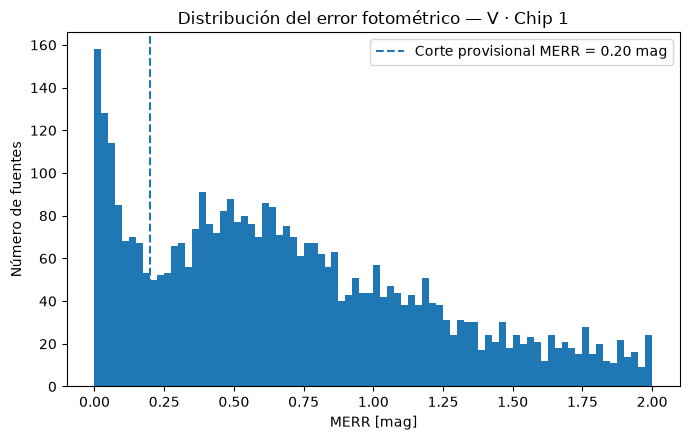

In [54]:
plt.figure(figsize=(7, 4.5))

plt.hist(
    df_valid["merr"],
    bins=80,
    range=(0, 2)
)

plt.axvline(
    0.20,
    linestyle="--",
    label="Corte provisional MERR = 0.20 mag"
)

plt.xlabel("MERR [mag]")
plt.ylabel("Número de fuentes")
plt.title("Distribución del error fotométrico — V · Chip 1")
plt.legend()
plt.tight_layout()
plt.show()


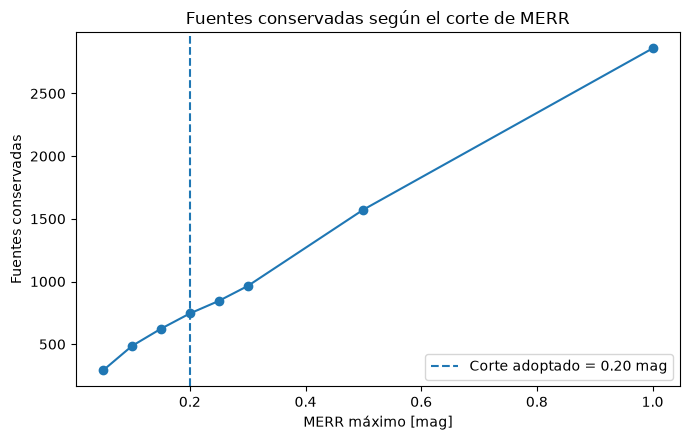

In [55]:
plt.figure(figsize=(7, 4.5))

plt.plot(
    tabla_cortes_merr["MERR_max"],
    tabla_cortes_merr["N_fuentes"],
    marker="o"
)

plt.axvline(
    0.20,
    linestyle="--",
    label="Corte adoptado = 0.20 mag"
)

plt.xlabel("MERR máximo [mag]")
plt.ylabel("Fuentes conservadas")
plt.title("Fuentes conservadas según el corte de MERR")
plt.legend()
plt.tight_layout()
plt.show()


### Criterio de calidad fotométrica para V · Chip 1

Se evaluaron diferentes límites superiores para el error fotométrico `MERR`.

La cantidad de fuentes conservadas disminuye rápidamente al exigir errores fotométricos más pequeños. En particular, para:

$$
MERR\leq0.20\ \mathrm{mag}
$$

se conservan:

$$
N=745
$$

fuentes de las \(5047\) fuentes con magnitud y error fotométrico definidos.

Esto corresponde a:

$$
\frac{745}{5047}\times100
=
14.76\%.
$$

Utilizando la relación aproximada:

$$
S/N\approx\frac{1.0857}{MERR},
$$

el límite:

$$
MERR=0.20\ \mathrm{mag}
$$

equivale aproximadamente a:

$$
S/N\approx5.43.
$$

Por esta razón se adopta provisionalmente:

$$
\boxed{MERR\leq0.20\ \mathrm{mag}}
$$

para construir una muestra fotométrica de alta calidad con la cual evaluar inicialmente la contaminación producida por fuentes vecinas y por el anillo de cielo.

Este criterio se utiliza como una selección de calidad para la etapa de validación y no implica que las fuentes con errores superiores deban ser descartadas definitivamente del análisis.

In [56]:
df_calidad = df_valid[
    df_valid["merr"] <= 0.20
].copy()

print("Fuentes con MAG y MERR válidos :", len(df_valid))
print("Fuentes con MERR <= 0.20       :", len(df_calidad))

print(
    "Porcentaje:",
    f"{100 * len(df_calidad) / len(df_valid):.2f}%"
)

Fuentes con MAG y MERR válidos : 5047
Fuentes con MERR <= 0.20       : 745
Porcentaje: 14.76%


In [57]:
archivo_calidad = (
    base
    / "chips"
    / "chip1"
    / "V_chip1_quality.dat"
)

df_calidad.to_csv(
    archivo_calidad,
    sep=" ",
    index=False,
    float_format="%.5f"
)

archivo_xy_calidad = (
    base
    / "chips"
    / "chip1"
    / "V_chip1_quality.xy"
)

df_calidad[["x", "y"]].to_csv(
    archivo_xy_calidad,
    sep=" ",
    index=False,
    header=False,
    float_format="%.3f"
)

print("Catálogo completo:", archivo_calidad)
print("Coordenadas:", archivo_xy_calidad)

Catálogo completo: /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip1/V_chip1_quality.dat
Coordenadas: /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip1/V_chip1_quality.xy


### Evaluación de contaminación por fuentes vecinas

La selección mediante `MERR` garantiza una muestra con buena calidad fotométrica, pero no garantiza que las fuentes estén aisladas.

Una fuente cercana puede aportar flujo dentro de la apertura de la estrella objetivo y producir una medición contaminada.

El radio de apertura adoptado es:

$$
r_{\mathrm{ap}}=13.53\ \mathrm{pix}.
$$

Por esta razón se utiliza inicialmente como distancia crítica:

$$
d_{\mathrm{crit}}=r_{\mathrm{ap}}.
$$

Por tanto:

$$
\boxed{d_{\mathrm{crit}}=13.53\ \mathrm{pix}}
$$

Una fuente será considerada aislada si la distancia a la detección vecina más cercana satisface:

$$
d_{\mathrm{vecino}}>13.53\ \mathrm{pix}.
$$

Para identificar correctamente los vecinos, cada fuente de la muestra de calidad se compara contra el catálogo completo de detecciones producido por `DAOFIND`, y no únicamente contra las fuentes que superaron el criterio de calidad fotométrica.

In [58]:
from scipy.spatial import cKDTree
import numpy as np

# ---------------------------------------------------------
# Objetivos:
# 745 fuentes con MERR <= 0.20
# ---------------------------------------------------------

targets = df_calidad[["x", "y"]].to_numpy()

# ---------------------------------------------------------
# Pool de vecinos:
# catálogo COMPLETO de DAOFIND con threshold = 3.55
# ---------------------------------------------------------

pool = catalogo[["x", "y"]].to_numpy()

tree = cKDTree(pool)

# k=2:
# el primer vecino debe ser la propia detección
# el segundo corresponde a la fuente distinta más cercana
distancias, indices = tree.query(targets, k=2)

d_match = distancias[:, 0]
d_vecino = distancias[:, 1]

print("Número de estrellas objetivo:", len(targets))
print()
print("Máxima distancia al match propio:", d_match.max())
print("Mediana distancia al vecino:", np.median(d_vecino))
print("Mínima distancia al vecino:", d_vecino.min())
print("Máxima distancia al vecino:", d_vecino.max())

Número de estrellas objetivo: 745

Máxima distancia al match propio: 0.0
Mediana distancia al vecino: 14.356595870888052
Mínima distancia al vecino: 0.6002341209896155
Máxima distancia al vecino: 129.65258162103805


In [59]:
d_crit = 13.53

df_calidad["d_vecino"] = d_vecino

mask_aislada = df_calidad["d_vecino"] > d_crit

df_aisladas = df_calidad[mask_aislada].copy()
df_vecinos = df_calidad[~mask_aislada].copy()

print("Muestra de calidad :", len(df_calidad))
print("Aisladas           :", len(df_aisladas))
print("Rechazadas vecino  :", len(df_vecinos))

print()
print(
    "Porcentaje aisladas:",
    f"{100 * len(df_aisladas) / len(df_calidad):.2f}%"
)

Muestra de calidad : 745
Aisladas           : 385
Rechazadas vecino  : 360

Porcentaje aisladas: 51.68%


**### Visualización de las distancias a la fuente vecina más cercana**

La distribución de \(d_{\mathrm{vecino}}\) permite comparar directamente las separaciones entre fuentes con el radio crítico utilizado para definir aislamiento.


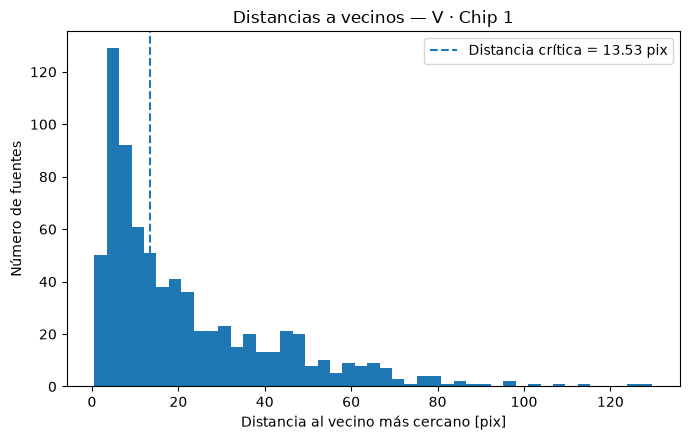

In [60]:
plt.figure(figsize=(7, 4.5))

plt.hist(
    df_calidad["d_vecino"],
    bins=45
)

plt.axvline(
    d_crit,
    linestyle="--",
    label=f"Distancia crítica = {d_crit:.2f} pix"
)

plt.xlabel("Distancia al vecino más cercano [pix]")
plt.ylabel("Número de fuentes")
plt.title("Distancias a vecinos — V · Chip 1")
plt.legend()
plt.tight_layout()
plt.show()


### Resultado del análisis de fuentes vecinas para V · Chip 1

La búsqueda de vecinos se realizó comparando las \(745\) fuentes de la muestra de calidad contra el catálogo completo generado por `DAOFIND`.

Para cada estrella se identificaron los dos objetos más cercanos utilizando un árbol `cKDTree`. El primer objeto corresponde a la propia fuente y el segundo corresponde a la detección distinta más cercana.

La distancia máxima encontrada entre cada estrella de la muestra y su propia detección en el catálogo completo fue:

$$
d_{\mathrm{match,max}}=0.0\ \mathrm{pix}
$$

lo cual confirma una correspondencia exacta entre ambos catálogos.

La mediana de la distancia al vecino más cercano fue:

$$
\mathrm{mediana}(d_{\mathrm{vecino}})
=
14.36\ \mathrm{pix}.
$$

La distancia mínima encontrada fue:

$$
d_{\mathrm{vecino,min}}
=
0.60\ \mathrm{pix}
$$

mientras que la máxima fue:

$$
d_{\mathrm{vecino,max}}
=
129.65\ \mathrm{pix}.
$$

Se adoptó como distancia crítica el radio de apertura:

$$
d_{\mathrm{crit}}
=
r_{\mathrm{ap}}
=
13.53\ \mathrm{pix}.
$$

Una fuente se consideró aislada cuando:

$$
d_{\mathrm{vecino}}>13.53\ \mathrm{pix}.
$$

De las \(745\) fuentes de alta calidad:

$$
N_{\mathrm{aisladas}}=385
$$

cumplieron este criterio, mientras que:

$$
N_{\mathrm{rechazadas}}=360
$$

fueron excluidas debido a la presencia de una detección vecina dentro de la región crítica.

La fracción de fuentes aisladas fue:

$$
\frac{385}{745}\times100
=
51.68\%.
$$

Por lo tanto:

$$
\boxed{51.68\%}
$$

de las fuentes de alta calidad permanecen disponibles para estudiar la contaminación del anillo de cielo.

In [61]:
archivo_aisladas = (
    base
    / "chips"
    / "chip1"
    / "V_chip1_aisladas.dat"
)

archivo_vecinos = (
    base
    / "chips"
    / "chip1"
    / "V_chip1_rechazadas_vecino.dat"
)

df_aisladas.to_csv(
    archivo_aisladas,
    sep=" ",
    index=False,
    float_format="%.5f"
)

df_vecinos.to_csv(
    archivo_vecinos,
    sep=" ",
    index=False,
    float_format="%.5f"
)

print("Aisladas:", archivo_aisladas)
print("Rechazadas por vecino:", archivo_vecinos)

Aisladas: /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip1/V_chip1_aisladas.dat
Rechazadas por vecino: /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip1/V_chip1_rechazadas_vecino.dat


### Evaluación de contaminación en el anillo fijo de cielo

Después de eliminar las fuentes con vecinos cercanos, se analizaron las \(385\) estrellas aisladas con el objetivo de determinar si el anillo fijo utilizado para estimar el cielo contiene señal contaminante.

El anillo de referencia está definido por:

$$
r_{\mathrm{in}}=22.55\ \mathrm{pix}
$$

y:

$$
r_{\mathrm{out}}=37.55\ \mathrm{pix}.
$$

Para cada estrella se extrajeron los valores de todos los píxeles contenidos en este anillo.

La distribución de intensidades de cada anillo se caracterizó mediante los cuartiles:

$$
Q_1
$$

y:

$$
Q_3.
$$

Se calculó el rango intercuartílico:

$$
IQR=Q_3-Q_1.
$$

Un píxel fue identificado como anormalmente brillante cuando:

$$
I>Q_3+1.5\,IQR.
$$

Posteriormente se definió, para cada estrella, la fracción de píxeles altos:

$$
f_{\mathrm{out}}
=
\frac{N_{\mathrm{out}}}{N_{\mathrm{sky}}},
$$

donde \(N_{\mathrm{out}}\) corresponde al número de píxeles que superan el límite superior de Tukey y \(N_{\mathrm{sky}}\) es el número total de píxeles válidos contenidos en el anillo.

Esta cantidad permite estimar de manera robusta el grado de contaminación presente en el anillo de cielo de cada fuente.

In [62]:
import numpy as np
import pandas as pd
from astropy.io import fits

# Imagen V - Chip 1
imagen = fits.getdata(
    base / "chips/chip1/SexA_V_chip1.fits"
).astype(float)

ny, nx = imagen.shape

# Anillo fijo
r_in = 22.55
r_out = 37.55

resultados_anillo = []

for idx, fila in df_aisladas.iterrows():

    # IRAF usa coordenadas 1-based
    x = float(fila["x"]) - 1
    y = float(fila["y"]) - 1

    # Caja mínima que contiene el anillo
    xmin = max(0, int(np.floor(x - r_out)))
    xmax = min(nx, int(np.ceil(x + r_out)) + 1)

    ymin = max(0, int(np.floor(y - r_out)))
    ymax = min(ny, int(np.ceil(y + r_out)) + 1)

    sub = imagen[ymin:ymax, xmin:xmax]

    yy, xx = np.indices(sub.shape)

    xx_global = xx + xmin
    yy_global = yy + ymin

    r = np.sqrt(
        (xx_global - x)**2 +
        (yy_global - y)**2
    )

    mask_anillo = (
        (r >= r_in) &
        (r <= r_out)
    )

    valores = sub[mask_anillo]

    # Excluir valores inválidos si apareciera alguno
    valores = valores[
        np.isfinite(valores) &
        (valores != 50000)
    ]

    if len(valores) == 0:
        continue

    Q1 = np.percentile(valores, 25)
    Q3 = np.percentile(valores, 75)

    IQR = Q3 - Q1

    limite_alto = Q3 + 1.5 * IQR

    n_sky = len(valores)
    n_out = np.sum(valores > limite_alto)

    f_out = n_out / n_sky

    resultados_anillo.append({
        "x": fila["x"],
        "y": fila["y"],
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "limite_alto": limite_alto,
        "N_sky": n_sky,
        "N_out": n_out,
        "f_out": f_out
    })

df_anillos = pd.DataFrame(resultados_anillo)

print("Estrellas analizadas:", len(df_anillos))

df_anillos.head()

Estrellas analizadas: 385


,x,y,Q1,Q3,IQR,limite_alto,N_sky,N_out,f_out
0,3608.470,119.523,-4.953953,2.291291,7.245244,13.159157,2840,20,0.007042
1,1500.848,119.675,-5.685638,2.089136,7.774775,13.751298,2827,20,0.007075
2,2631.573,125.332,-5.284801,1.638985,6.923785,12.024662,2834,31,0.010939
3,1083.038,145.822,-5.700787,1.630871,7.331657,12.628357,2835,11,0.003880
4,3044.895,147.519,-4.983601,1.458263,6.441864,11.121059,2831,8,0.002826


In [63]:
print(
    df_anillos["f_out"].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

count    385.000000
mean       0.014613
std        0.025358
min        0.001059
25%        0.003881
50%        0.005302
75%        0.010608
90%        0.034552
95%        0.071279
99%        0.128629
max        0.151504
Name: f_out, dtype: float64


In [64]:
f = df_anillos["f_out"].to_numpy()

Q1_f = np.percentile(f, 25)
Q3_f = np.percentile(f, 75)

IQR_f = Q3_f - Q1_f

f_lim = Q3_f + 1.5 * IQR_f

print(f"Q1(f_out) = {Q1_f:.6f}")
print(f"Q3(f_out) = {Q3_f:.6f}")
print(f"IQR       = {IQR_f:.6f}")
print(f"Límite    = {f_lim:.6f}")

print()
print(
    "Límite porcentual =",
    f"{100*f_lim:.2f}%"
)

Q1(f_out) = 0.003881
Q3(f_out) = 0.010608
IQR       = 0.006727
Límite    = 0.020698

Límite porcentual = 2.07%


### Determinación del límite de contaminación del anillo para V · Chip 1

Para cada una de las $385$ fuentes aisladas se calculó la fracción de píxeles anormalmente altos dentro del anillo de cielo:

$$
f_{\mathrm{out}}
=
\frac{N_{\mathrm{out}}}{N_{\mathrm{sky}}}.
$$

La distribución obtenida presentó una mediana de:

$$
\mathrm{mediana}(f_{\mathrm{out}})
=
0.005302
$$

equivalente aproximadamente a:

$$
0.53\%.
$$

El primer y tercer cuartil fueron:

$$
Q_1=0.003881
$$

y:

$$
Q_3=0.010608.
$$

Por tanto, el rango intercuartílico fue:

$$
IQR=Q_3-Q_1
$$

$$
IQR=0.006727.
$$

Para identificar anillos con una fracción anormalmente elevada de píxeles brillantes se aplicó nuevamente el criterio de Tukey:

$$
f_{\mathrm{lim}}
=
Q_3+1.5\,IQR.
$$

Sustituyendo los valores obtenidos:

$$
f_{\mathrm{lim}}
=
0.010608
+
1.5(0.006727)
$$

se obtiene:

$$
f_{\mathrm{lim}}
=
0.020698.
$$

Expresado en porcentaje:

$$
\boxed{f_{\mathrm{lim}}\approx2.07\%}
$$

Por lo tanto, para V · Chip 1 un anillo se considera limpio cuando:

$$
f_{\mathrm{out}}\leq0.020698
$$

y se considera contaminado cuando:

$$
f_{\mathrm{out}}>0.020698.
$$

Este límite se obtiene de forma empírica a partir de la distribución observada en este chip y será utilizado para decidir cuándo el anillo fijo debe ser desplazado en el procedimiento adaptativo.

In [65]:
f_lim = 0.020698

mask_cielo_limpio = (
    df_anillos["f_out"] <= f_lim
)

df_cielo_limpio = df_anillos[
    mask_cielo_limpio
].copy()

df_cielo_contaminado = df_anillos[
    ~mask_cielo_limpio
].copy()

print("Total analizadas :", len(df_anillos))
print("Cielo limpio     :", len(df_cielo_limpio))
print("Contaminadas     :", len(df_cielo_contaminado))

print()

print(
    "Porcentaje limpio:",
    f"{100 * len(df_cielo_limpio) / len(df_anillos):.2f}%"
)

print(
    "Porcentaje contaminado:",
    f"{100 * len(df_cielo_contaminado) / len(df_anillos):.2f}%"
)

Total analizadas : 385
Cielo limpio     : 323
Contaminadas     : 62

Porcentaje limpio: 83.90%
Porcentaje contaminado: 16.10%


In [66]:
archivo_cielo_limpio = (
    base
    / "chips"
    / "chip1"
    / "V_chip1_cielo_limpio.dat"
)

archivo_cielo_contaminado = (
    base
    / "chips"
    / "chip1"
    / "V_chip1_cielo_contaminado.dat"
)

df_cielo_limpio.to_csv(
    archivo_cielo_limpio,
    sep=" ",
    index=False,
    float_format="%.6f"
)

df_cielo_contaminado.to_csv(
    archivo_cielo_contaminado,
    sep=" ",
    index=False,
    float_format="%.6f"
)

print("Archivos guardados.")

Archivos guardados.


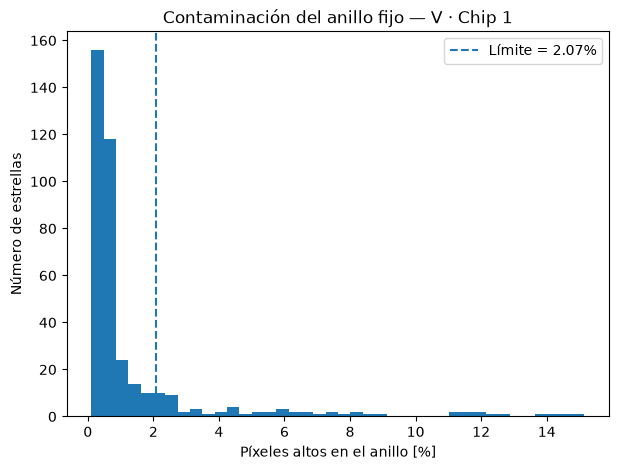

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.hist(
    df_anillos["f_out"] * 100,
    bins=40
)

plt.axvline(
    f_lim * 100,
    linestyle="--",
    label=f"Límite = {f_lim*100:.2f}%"
)

plt.xlabel("Píxeles altos en el anillo [%]")
plt.ylabel("Número de estrellas")
plt.title("Contaminación del anillo fijo — V · Chip 1")
plt.legend()

plt.show()

### Clasificación del anillo fijo para V · Chip 1

El límite empírico de contaminación determinado para este chip fue:

$$
f_{\mathrm{lim}}=0.020698
$$

equivalente a:

$$
f_{\mathrm{lim}}\approx2.07\%.
$$

Una fuente fue clasificada con cielo limpio cuando:

$$
f_{\mathrm{out}}\leq0.020698
$$

y como contaminada cuando:

$$
f_{\mathrm{out}}>0.020698.
$$

De las \(385\) fuentes aisladas analizadas:

$$
N_{\mathrm{limpias}}=323
$$

presentaron un anillo fijo aceptable, mientras que:

$$
N_{\mathrm{contaminadas}}=62
$$

superaron el límite de contaminación.

Por lo tanto:

$$
\frac{323}{385}\times100=83.90\%
$$

de las fuentes presentan un anillo fijo limpio, mientras que:

$$
\frac{62}{385}\times100=16.10\%
$$

requieren evaluar una posición alternativa del anillo de cielo.

Los resultados obtenidos son:

$$
\boxed{83.90\%\ \text{con cielo limpio}}
$$

y:

$$
\boxed{16.10\%\ \text{con cielo contaminado}}.
$$

### Procedimiento adaptativo para la selección del anillo de cielo

Las fuentes cuyo anillo inicial supera el límite de contaminación requieren evaluar regiones de cielo alternativas.

El anillo fijo de referencia es:

$$
22.55\leq r\leq37.55\ \mathrm{pix}.
$$

Para mantener constante el número aproximado de píxeles utilizados en la estimación del cielo, se conserva un ancho de:

$$
\Delta r_{\mathrm{sky}}=15\ \mathrm{pix}.
$$

Cuando el anillo inicial presenta:

$$
f_{\mathrm{out}}>f_{\mathrm{lim}},
$$

el radio interno se desplaza hacia afuera en pasos de:

$$
\Delta r=5\ \mathrm{pix}.
$$

Las configuraciones evaluadas son:

$$
22.55-37.55\ \mathrm{pix}
$$

$$
27.55-42.55\ \mathrm{pix}
$$

$$
32.55-47.55\ \mathrm{pix}
$$

$$
37.55-52.55\ \mathrm{pix}
$$

$$
42.55-57.55\ \mathrm{pix}.
$$

Para cada fuente se selecciona el primer anillo, comenzando desde el más cercano, que satisfaga:

$$
f_{\mathrm{out}}\leq f_{\mathrm{lim}}.
$$

Con este criterio se busca conservar la mayor localidad posible en la estimación del cielo y desplazar el anillo únicamente cuando la región original presenta evidencia de contaminación.

Los pasos de \(5\) píxeles y el ancho de \(15\) píxeles constituyen parámetros operacionales del procedimiento y deberán ser evaluados posteriormente durante la validación del método.

In [68]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Parámetros del método adaptativo
# ---------------------------------------------------------

f_lim = 0.020698
ancho_anillo = 15.0

radios_internos = [
    22.55,
    27.55,
    32.55,
    37.55,
    42.55
]

radios = [
    (rin, rin + ancho_anillo)
    for rin in radios_internos
]

print("Anillos candidatos:")

for rin, rout in radios:
    print(f"{rin:.2f} - {rout:.2f} pix")

Anillos candidatos:
22.55 - 37.55 pix
27.55 - 42.55 pix
32.55 - 47.55 pix
37.55 - 52.55 pix
42.55 - 57.55 pix


In [69]:
def evaluar_anillo(imagen, x_iraf, y_iraf, r_in, r_out):

    ny, nx = imagen.shape

    # Conversión IRAF (1-based) -> NumPy (0-based)
    x = float(x_iraf) - 1
    y = float(y_iraf) - 1

    # Verificar que el círculo completo cabe en la imagen
    if (
        x - r_out < 0 or
        x + r_out >= nx or
        y - r_out < 0 or
        y + r_out >= ny
    ):
        return None

    xmin = int(np.floor(x - r_out))
    xmax = int(np.ceil(x + r_out)) + 1

    ymin = int(np.floor(y - r_out))
    ymax = int(np.ceil(y + r_out)) + 1

    sub = imagen[ymin:ymax, xmin:xmax]

    yy, xx = np.indices(sub.shape)

    xx_global = xx + xmin
    yy_global = yy + ymin

    r = np.sqrt(
        (xx_global - x)**2 +
        (yy_global - y)**2
    )

    mask_anillo = (
        (r >= r_in) &
        (r <= r_out)
    )

    valores = sub[mask_anillo]

    # Si el anillo contiene píxeles 50000,
    # no se considera geométricamente válido.
    if np.any(valores == 50000):
        return None

    valores = valores[np.isfinite(valores)]

    if len(valores) == 0:
        return None

    Q1 = np.percentile(valores, 25)
    Q3 = np.percentile(valores, 75)

    IQR = Q3 - Q1

    limite_alto = Q3 + 1.5 * IQR

    n_sky = len(valores)
    n_out = np.sum(valores > limite_alto)

    f_out = n_out / n_sky

    return {
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "limite_alto": limite_alto,
        "N_sky": n_sky,
        "N_out": n_out,
        "f_out": f_out
    }

In [70]:
resultados_adaptativos = []

for _, estrella in df_aisladas.iterrows():

    x = estrella["x"]
    y = estrella["y"]

    solucion = None
    hubo_anillo_valido = False

    for r_in, r_out in radios:

        resultado = evaluar_anillo(
            imagen,
            x,
            y,
            r_in,
            r_out
        )

        # El anillo no cabe o intersecta 50000
        if resultado is None:
            continue

        hubo_anillo_valido = True

        # Primer anillo que cumple el criterio
        if resultado["f_out"] <= f_lim:

            solucion = {
                "x": x,
                "y": y,
                "r_in": r_in,
                "r_out": r_out,
                "f_out": resultado["f_out"],
                "N_sky": resultado["N_sky"],
                "N_out": resultado["N_out"],
                "estado": "aceptado"
            }

            break

    # Si ninguno de los anillos fue aceptable
    if solucion is None:

        if hubo_anillo_valido:
            estado = "contaminado_hasta_r57"
        else:
            estado = "sin_solucion_geometrica"

        solucion = {
            "x": x,
            "y": y,
            "r_in": np.nan,
            "r_out": np.nan,
            "f_out": np.nan,
            "N_sky": np.nan,
            "N_out": np.nan,
            "estado": estado
        }

    resultados_adaptativos.append(solucion)

df_adapt = pd.DataFrame(resultados_adaptativos)

df_adapt.head()

,x,y,r_in,r_out,f_out,N_sky,N_out,estado
0,3608.470,119.523,22.55,37.55,0.007042,2840.0,20.0,aceptado
1,1500.848,119.675,22.55,37.55,0.007075,2827.0,20.0,aceptado
2,2631.573,125.332,22.55,37.55,0.010939,2834.0,31.0,aceptado
3,1083.038,145.822,22.55,37.55,0.003880,2835.0,11.0,aceptado
4,3044.895,147.519,22.55,37.55,0.002826,2831.0,8.0,aceptado


In [71]:
print("Total de estrellas:", len(df_adapt))
print()

print(df_adapt["estado"].value_counts())

print()

aceptadas = df_adapt[
    df_adapt["estado"] == "aceptado"
]

print("Aceptadas con algún anillo:", len(aceptadas))

print(
    "Porcentaje aceptado:",
    f"{100 * len(aceptadas) / len(df_adapt):.2f}%"
)

print()
print("Distribución de anillos seleccionados:")

print(
    aceptadas
    .groupby(["r_in", "r_out"])
    .size()
)

Total de estrellas: 385

estado
aceptado                 366
contaminado_hasta_r57     19
Name: count, dtype: int64

Aceptadas con algún anillo: 366
Porcentaje aceptado: 95.06%

Distribución de anillos seleccionados:
r_in   r_out
22.55  37.55    323
27.55  42.55     17
32.55  47.55      7
37.55  52.55      8
42.55  57.55     11
dtype: int64


**### Visualización de los anillos seleccionados por el método adaptativo**

La gráfica resume cuántas fuentes conservaron el anillo fijo y cuántas requirieron desplazamientos progresivos hacia regiones más externas.


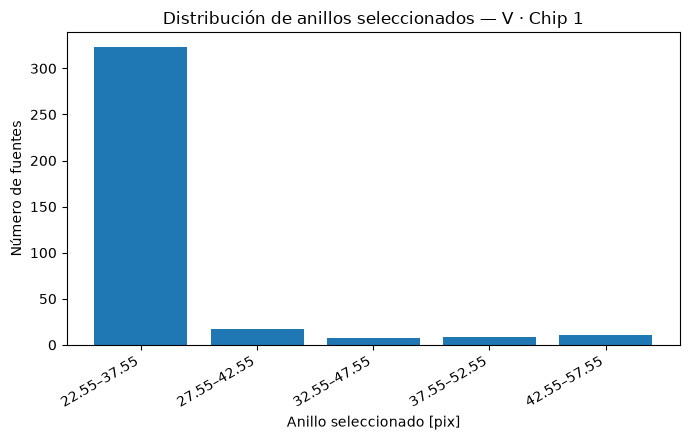

In [72]:
conteo_anillos = (
    aceptadas
    .groupby(["r_in", "r_out"])
    .size()
)

etiquetas_anillos = [
    f"{rin:.2f}–{rout:.2f}"
    for rin, rout in conteo_anillos.index
]

plt.figure(figsize=(7, 4.5))

plt.bar(
    etiquetas_anillos,
    conteo_anillos.values
)

plt.xlabel("Anillo seleccionado [pix]")
plt.ylabel("Número de fuentes")
plt.title("Distribución de anillos seleccionados — V · Chip 1")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


### Resultado de la selección adaptativa del anillo para V · Chip 1

El procedimiento adaptativo se aplicó sobre las \(385\) estrellas aisladas utilizadas para analizar la contaminación del cielo.

Con el anillo fijo inicial:

$$
22.55\leq r\leq37.55\ \mathrm{pix}
$$

se habían identificado:

$$
N_{\mathrm{limpias}}=323
$$

fuentes con un anillo aceptable y:

$$
N_{\mathrm{contaminadas}}=62
$$

fuentes cuyo valor de contaminación superaba:

$$
f_{\mathrm{lim}}=0.020698.
$$

Para estas fuentes se evaluaron progresivamente anillos desplazados hacia afuera, conservando un ancho constante de \(15\) píxeles.

La distribución de los anillos finalmente seleccionados fue:

$$
22.55-37.55:\quad323
$$

$$
27.55-42.55:\quad17
$$

$$
32.55-47.55:\quad7
$$

$$
37.55-52.55:\quad8
$$

$$
42.55-57.55:\quad11.
$$

En total, el procedimiento encontró un anillo aceptable para:

$$
N_{\mathrm{aceptadas}}=366
$$

de las \(385\) estrellas analizadas.

Por lo tanto:

$$
\frac{366}{385}\times100
=
95.06\%.
$$

Así, después de aplicar la selección adaptativa:

$$
\boxed{95.06\%}
$$

de las fuentes aisladas disponen de un anillo de cielo que satisface el criterio de contaminación.

### Recuperación de fuentes inicialmente contaminadas

De las \(62\) fuentes cuyo anillo fijo inicial fue clasificado como contaminado, el método adaptativo encontró una configuración alternativa aceptable para:

$$
N_{\mathrm{recuperadas}}
=
17+7+8+11
=
43.
$$

La tasa de recuperación entre las fuentes inicialmente contaminadas es:

$$
\frac{43}{62}\times100
=
69.35\%.
$$

Por lo tanto:

$$
\boxed{69.35\%}
$$

de las fuentes inicialmente afectadas por contaminación en el anillo fijo pudieron recuperar una región de cielo aceptable mediante el desplazamiento adaptativo.

Las \(19\) fuentes restantes no encontraron un anillo que cumpliera el criterio dentro del intervalo máximo evaluado:

$$
r_{\mathrm{out}}\leq57.55\ \mathrm{pix}.
$$

Estas fuentes no se consideran necesariamente imposibles de medir, sino que no presentan una solución aceptable dentro del conjunto de anillos evaluado en este procedimiento.

In [73]:
# Resumen del procedimiento adaptativo

n_total = len(df_adapt)
n_fijo_limpio = 323
n_inicial_contaminado = 62

n_adapt_aceptado = (
    df_adapt["estado"] == "aceptado"
).sum()

n_recuperadas = n_adapt_aceptado - n_fijo_limpio

n_sin_solucion = n_total - n_adapt_aceptado

tasa_recuperacion = (
    100 * n_recuperadas / n_inicial_contaminado
)

print("Total analizadas              :", n_total)
print("Limpias con anillo fijo       :", n_fijo_limpio)
print("Inicialmente contaminadas     :", n_inicial_contaminado)
print("Recuperadas por adaptación    :", n_recuperadas)
print("Sin solución entre candidatas :", n_sin_solucion)

print()
print(
    "Tasa de recuperación:",
    f"{tasa_recuperacion:.2f}%"
)

Total analizadas              : 385
Limpias con anillo fijo       : 323
Inicialmente contaminadas     : 62
Recuperadas por adaptación    : 43
Sin solución entre candidatas : 19

Tasa de recuperación: 69.35%


In [74]:
archivo_adapt = (
    base
    / "chips"
    / "chip1"
    / "V_chip1_anillo_adaptativo.dat"
)

df_adapt.to_csv(
    archivo_adapt,
    sep=" ",
    index=False,
    float_format="%.6f"
)

print(archivo_adapt)

/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip1/V_chip1_anillo_adaptativo.dat


In [75]:
grupos_anillo = [
    (22.55, 37.55),
    (27.55, 42.55),
    (32.55, 47.55),
    (37.55, 52.55),
    (42.55, 57.55)
]

for r_in, r_out in grupos_anillo:

    grupo = df_adapt[
        (df_adapt["estado"] == "aceptado") &
        np.isclose(df_adapt["r_in"], r_in) &
        np.isclose(df_adapt["r_out"], r_out)
    ].copy()

    nombre = (
        base
        / "chips"
        / "chip1"
        / f"V_chip1_adapt_r{r_in:.2f}_{r_out:.2f}.coo"
    )

    grupo[["x", "y"]].to_csv(
        nombre,
        sep=" ",
        index=False,
        header=False,
        float_format="%.3f"
    )

    print(
        f"{r_in:.2f}-{r_out:.2f}: "
        f"{len(grupo)} estrellas -> {nombre.name}"
    )

22.55-37.55: 323 estrellas -> V_chip1_adapt_r22.55_37.55.coo
27.55-42.55: 17 estrellas -> V_chip1_adapt_r27.55_42.55.coo
32.55-47.55: 7 estrellas -> V_chip1_adapt_r32.55_47.55.coo
37.55-52.55: 8 estrellas -> V_chip1_adapt_r37.55_52.55.coo
42.55-57.55: 11 estrellas -> V_chip1_adapt_r42.55_57.55.coo


### Fotometría con anillo adaptativo para V · Chip 1

El procedimiento adaptativo encontró un anillo aceptable para:

$$
N_{\mathrm{adapt}}=366
$$

de las \(385\) fuentes aisladas analizadas.

Estas fuentes se distribuyeron entre cinco configuraciones de anillo:

$$
22.55-37.55:\quad323
$$

$$
27.55-42.55:\quad17
$$

$$
32.55-47.55:\quad7
$$

$$
37.55-52.55:\quad8
$$

$$
42.55-57.55:\quad11.
$$

Debido a que `PHOT` utiliza un único valor de `annulus` para cada ejecución, las fuentes se dividieron en grupos según el anillo seleccionado por el algoritmo adaptativo.

La apertura estelar se mantuvo constante para todos los grupos:

$$
r_{\mathrm{ap}}=13.53\ \mathrm{pix}.
$$

También se mantuvieron constantes los demás parámetros fotométricos, modificando únicamente la posición del anillo de cielo.

Esto permite comparar directamente la fotometría obtenida con el anillo fijo y con el anillo seleccionado por el procedimiento adaptativo.

In [76]:
from pathlib import Path
import pandas as pd
import numpy as np

cols = [
    "x",
    "y",
    "msky",
    "stdev",
    "nsky",
    "flux",
    "mag",
    "merr"
]

archivos_adapt = {
    "22.55-37.55": base / "chips/chip1/V_chip1_adapt_r22_55_37_55.dat",
    "27.55-42.55": base / "chips/chip1/V_chip1_adapt_r27_55_42_55.dat",
    "32.55-47.55": base / "chips/chip1/V_chip1_adapt_r32_55_47_55.dat",
    "37.55-52.55": base / "chips/chip1/V_chip1_adapt_r37_55_52_55.dat",
    "42.55-57.55": base / "chips/chip1/V_chip1_adapt_r42_55_57_55.dat"
}

grupos = []

for anillo, archivo in archivos_adapt.items():

    temp = pd.read_csv(
        archivo,
        sep=r"\s+",
        names=cols,
        na_values="INDEF"
    )

    temp["anillo"] = anillo

    grupos.append(temp)

df_phot_adapt = pd.concat(
    grupos,
    ignore_index=True
)

print("Total fotometrías adaptativas:", len(df_phot_adapt))

print()
print(df_phot_adapt["anillo"].value_counts().sort_index())

Total fotometrías adaptativas: 366

anillo
22.55-37.55    323
27.55-42.55     17
32.55-47.55      7
37.55-52.55      8
42.55-57.55     11
Name: count, dtype: int64


### Ejecución de la fotometría adaptativa para V · Chip 1

Las \(366\) fuentes para las cuales el procedimiento encontró un anillo aceptable fueron separadas en cinco grupos según la posición seleccionada para el anillo de cielo.

Las ejecuciones independientes de `PHOT` produjeron:

$$
22.55-37.55:\quad323
$$

$$
27.55-42.55:\quad17
$$

$$
32.55-47.55:\quad7
$$

$$
37.55-52.55:\quad8
$$

$$
42.55-57.55:\quad11.
$$

El número total de fuentes procesadas fue:

$$
323+17+7+8+11=366.
$$

Por lo tanto:

$$
\boxed{N_{\mathrm{phot,adapt}}=366}
$$

y el número de fuentes procesadas coincide exactamente con el número de fuentes para las cuales el algoritmo adaptativo encontró una solución.

In [77]:
from scipy.spatial import cKDTree

# Solo posiciones válidas en el catálogo fijo
fixed_pos = df[["x", "y"]].to_numpy()
adapt_pos = df_phot_adapt[["x", "y"]].to_numpy()

tree_fixed = cKDTree(fixed_pos)

dist_match, idx_fixed = tree_fixed.query(
    adapt_pos,
    k=1
)

print("Número de matches:", len(dist_match))
print("Distancia mínima :", dist_match.min())
print("Distancia mediana:", np.median(dist_match))
print("Distancia máxima :", dist_match.max())

Número de matches: 366
Distancia mínima : 0.0
Distancia mediana: 0.0
Distancia máxima : 0.0


In [78]:
df_comp = df_phot_adapt.copy()

df_comp["dist_match"] = dist_match

df_comp["mag_fixed"] = (
    df.iloc[idx_fixed]["mag"].to_numpy()
)

df_comp["merr_fixed"] = (
    df.iloc[idx_fixed]["merr"].to_numpy()
)

df_comp["msky_fixed"] = (
    df.iloc[idx_fixed]["msky"].to_numpy()
)

df_comp["stdev_fixed"] = (
    df.iloc[idx_fixed]["stdev"].to_numpy()
)

df_comp["flux_fixed"] = (
    df.iloc[idx_fixed]["flux"].to_numpy()
)

# Renombrar cantidades adaptativas
df_comp = df_comp.rename(columns={
    "mag": "mag_adapt",
    "merr": "merr_adapt",
    "msky": "msky_adapt",
    "stdev": "stdev_adapt",
    "flux": "flux_adapt"
})

df_comp.head()

,x,y,msky_adapt,stdev_adapt,nsky,flux_adapt,mag_adapt,merr_adapt,anillo,dist_match,mag_fixed,merr_fixed,msky_fixed,stdev_fixed,flux_fixed
0,3608.470,119.523,-1.410951,5.411946,2820,1077.5090,17.419,0.145,22.55-37.55,0.0,17.419,0.145,-1.410951,5.411946,1077.5090
1,1500.848,119.675,-1.888584,5.966805,2810,2149.2400,16.669,0.081,22.55-37.55,0.0,16.669,0.081,-1.888584,5.966805,2149.2400
2,2631.573,125.332,-1.832699,5.228755,2809,912.5795,17.599,0.165,22.55-37.55,0.0,17.599,0.165,-1.832699,5.228755,912.5795
3,1083.038,145.822,-2.213431,5.310680,2821,939.9342,17.567,0.163,22.55-37.55,0.0,17.567,0.163,-2.213431,5.310680,939.9342
4,3044.895,147.519,-1.718697,4.742019,2823,3088.1280,16.276,0.045,22.55-37.55,0.0,16.276,0.045,-1.718697,4.742019,3088.1280


In [79]:
control = df_comp[
    df_comp["anillo"] == "22.55-37.55"
].copy()

# Solo casos donde ambas fotometrías estén definidas
control_valid = control[
    control["mag_fixed"].notna() &
    control["mag_adapt"].notna() &
    control["merr_fixed"].notna() &
    control["merr_adapt"].notna()
].copy()

control_valid["delta_mag"] = (
    control_valid["mag_adapt"]
    - control_valid["mag_fixed"]
)

control_valid["delta_merr"] = (
    control_valid["merr_adapt"]
    - control_valid["merr_fixed"]
)

control_valid["delta_msky"] = (
    control_valid["msky_adapt"]
    - control_valid["msky_fixed"]
)

control_valid["delta_stdev"] = (
    control_valid["stdev_adapt"]
    - control_valid["stdev_fixed"]
)

control_valid["delta_flux"] = (
    control_valid["flux_adapt"]
    - control_valid["flux_fixed"]
)

print("Fuentes control totales :", len(control))
print("Control válidas         :", len(control_valid))

print()
print("Mediana ΔMAG   :", np.median(control_valid["delta_mag"]))
print("Máx |ΔMAG|     :", np.max(np.abs(control_valid["delta_mag"])))

print()
print("Mediana ΔMERR  :", np.median(control_valid["delta_merr"]))
print("Máx |ΔMERR|    :", np.max(np.abs(control_valid["delta_merr"])))

print()
print("Mediana ΔMSKY  :", np.median(control_valid["delta_msky"]))
print("Máx |ΔMSKY|    :", np.max(np.abs(control_valid["delta_msky"])))

print()
print("Mediana ΔFLUX  :", np.median(control_valid["delta_flux"]))

Fuentes control totales : 323
Control válidas         : 323

Mediana ΔMAG   : 0.0
Máx |ΔMAG|     : 0.0

Mediana ΔMERR  : 0.0
Máx |ΔMERR|    : 0.0

Mediana ΔMSKY  : 0.0
Máx |ΔMSKY|    : 0.0

Mediana ΔFLUX  : 0.0


### Prueba de control de la fotometría adaptativa

Antes de evaluar las fuentes cuyo anillo fue desplazado, se realizó una prueba de control utilizando las \(323\) estrellas para las cuales el algoritmo mantuvo el anillo original:

$$
22.55-37.55\ \mathrm{pix}.
$$

Estas fuentes fueron procesadas nuevamente con exactamente la misma apertura, el mismo anillo de cielo y la misma configuración de `PHOT` utilizada en la fotometría fija.

Por lo tanto, si ambas ejecuciones fueron realizadas bajo las mismas condiciones, se espera:

$$
\Delta MAG
=
MAG_{\mathrm{adapt}}-MAG_{\mathrm{fixed}}
\approx0
$$

$$
\Delta MERR
=
MERR_{\mathrm{adapt}}-MERR_{\mathrm{fixed}}
\approx0
$$

y:

$$
\Delta MSKY
=
MSKY_{\mathrm{adapt}}-MSKY_{\mathrm{fixed}}
\approx0.
$$

Esta comparación funciona como una prueba interna de reproducibilidad. Si las diferencias del grupo de control son despreciables, las variaciones observadas posteriormente en las fuentes con anillos desplazados pueden atribuirse al cambio en la selección del cielo y no a modificaciones accidentales de la configuración fotométrica.

### Resultado de la prueba de control

Las \(323\) fuentes cuyo anillo permaneció en la posición original fueron comparadas entre la fotometría fija y la nueva ejecución utilizada para el procedimiento adaptativo.

Las coordenadas de las fuentes coincidieron exactamente entre ambos catálogos:

$$
d_{\mathrm{match,min}}=0
$$

$$
d_{\mathrm{match,med}}=0
$$

$$
d_{\mathrm{match,max}}=0.
$$

Las \(323\) fuentes presentaron mediciones fotométricas válidas en ambas ejecuciones.

Las diferencias obtenidas fueron:

$$
\mathrm{mediana}(\Delta MAG)=0
$$

$$
\max(|\Delta MAG|)=0
$$

$$
\mathrm{mediana}(\Delta MERR)=0
$$

$$
\max(|\Delta MERR|)=0
$$

$$
\mathrm{mediana}(\Delta MSKY)=0
$$

$$
\max(|\Delta MSKY|)=0
$$

y:

$$
\mathrm{mediana}(\Delta FLUX)=0.
$$

Por lo tanto, la fotometría de control reproduce exactamente los resultados obtenidos con el anillo fijo.

Esto confirma que la configuración de `PHOT`, las coordenadas de las fuentes, el radio de apertura y los parámetros de estimación del cielo permanecieron constantes entre ambas ejecuciones.

En consecuencia, las diferencias que se encuentren para las fuentes cuyo anillo fue desplazado pueden asociarse al cambio en la región utilizada para estimar el cielo.

### Comparación fotométrica de las fuentes recuperadas mediante el anillo adaptativo

El procedimiento adaptativo modificó la posición del anillo de cielo para:

$$
N_{\mathrm{recuperadas}}=43
$$

fuentes que inicialmente presentaban un anillo contaminado.

Para estas fuentes se compararán directamente los resultados obtenidos con el anillo fijo y con el anillo seleccionado de manera adaptativa.

Para cada estrella se calcularán las diferencias:

$$
\Delta MSKY
=
MSKY_{\mathrm{adapt}}-MSKY_{\mathrm{fixed}}
$$

$$
\Delta STDEV
=
STDEV_{\mathrm{adapt}}-STDEV_{\mathrm{fixed}}
$$

$$
\Delta MAG
=
MAG_{\mathrm{adapt}}-MAG_{\mathrm{fixed}}
$$

$$
\Delta MERR
=
MERR_{\mathrm{adapt}}-MERR_{\mathrm{fixed}}
$$

y la razón entre los flujos:

$$
R_{\mathrm{flux}}
=
\frac{FLUX_{\mathrm{adapt}}}
{FLUX_{\mathrm{fixed}}}.
$$

También se estimará de manera aproximada la razón señal a ruido mediante:

$$
S/N\approx\frac{1.0857}{MERR}.
$$

Estas cantidades permitirán evaluar si la reducción de contaminación obtenida por el algoritmo adaptativo se traduce también en cambios favorables en la estimación del cielo y en la fotometría.

In [80]:
# ---------------------------------------------------------
# Fuentes cuyo anillo realmente fue desplazado
# ---------------------------------------------------------

adaptadas = df_comp[
    df_comp["anillo"] != "22.55-37.55"
].copy()

print("Fuentes con anillo desplazado:", len(adaptadas))

print()
print("Distribución por anillo:")
print(adaptadas["anillo"].value_counts().sort_index())

Fuentes con anillo desplazado: 43

Distribución por anillo:
anillo
27.55-42.55    17
32.55-47.55     7
37.55-52.55     8
42.55-57.55    11
Name: count, dtype: int64


In [81]:
columnas_comparacion = [
    "mag_fixed",
    "mag_adapt",
    "merr_fixed",
    "merr_adapt",
    "msky_fixed",
    "msky_adapt",
    "stdev_fixed",
    "stdev_adapt",
    "flux_fixed",
    "flux_adapt"
]

adaptadas_validas = adaptadas.dropna(
    subset=columnas_comparacion
).copy()

print("Fuentes desplazadas totales :", len(adaptadas))
print("Comparaciones completas      :", len(adaptadas_validas))
print("Con algún valor INDEF        :", len(adaptadas) - len(adaptadas_validas))

Fuentes desplazadas totales : 43
Comparaciones completas      : 43
Con algún valor INDEF        : 0


In [82]:
# Diferencias fijo -> adaptativo

adaptadas_validas["delta_msky"] = (
    adaptadas_validas["msky_adapt"]
    - adaptadas_validas["msky_fixed"]
)

adaptadas_validas["delta_stdev"] = (
    adaptadas_validas["stdev_adapt"]
    - adaptadas_validas["stdev_fixed"]
)

adaptadas_validas["delta_mag"] = (
    adaptadas_validas["mag_adapt"]
    - adaptadas_validas["mag_fixed"]
)

adaptadas_validas["delta_merr"] = (
    adaptadas_validas["merr_adapt"]
    - adaptadas_validas["merr_fixed"]
)

adaptadas_validas["flux_ratio"] = (
    adaptadas_validas["flux_adapt"]
    / adaptadas_validas["flux_fixed"]
)

# S/N aproximado
adaptadas_validas["snr_fixed"] = (
    1.0857 / adaptadas_validas["merr_fixed"]
)

adaptadas_validas["snr_adapt"] = (
    1.0857 / adaptadas_validas["merr_adapt"]
)

adaptadas_validas["delta_snr"] = (
    adaptadas_validas["snr_adapt"]
    - adaptadas_validas["snr_fixed"]
)

In [83]:
def sigma_mad(x):
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    return 1.4826 * np.nanmedian(np.abs(x - med))


print("Número de fuentes comparadas:", len(adaptadas_validas))

print("\n--- CIELO ---")
print(
    "Mediana ΔMSKY  =",
    np.median(adaptadas_validas["delta_msky"])
)
print(
    "Mediana ΔSTDEV =",
    np.median(adaptadas_validas["delta_stdev"])
)

print("\n--- MAGNITUD ---")
print(
    "Mediana ΔMAG =",
    np.median(adaptadas_validas["delta_mag"])
)
print(
    "Mediana |ΔMAG| =",
    np.median(np.abs(adaptadas_validas["delta_mag"]))
)
print(
    "Sigma MAD(ΔMAG) =",
    sigma_mad(adaptadas_validas["delta_mag"])
)

print("\n--- ERROR FOTOMÉTRICO ---")
print(
    "Mediana MERR fija  =",
    np.median(adaptadas_validas["merr_fixed"])
)
print(
    "Mediana MERR adapt =",
    np.median(adaptadas_validas["merr_adapt"])
)

n_merr_mejora = (
    adaptadas_validas["merr_adapt"]
    < adaptadas_validas["merr_fixed"]
).sum()

print(
    "MERR menor con adaptativo =",
    n_merr_mejora,
    "/",
    len(adaptadas_validas)
)

print(
    "Porcentaje con MERR menor =",
    f"{100*n_merr_mejora/len(adaptadas_validas):.2f}%"
)

print("\n--- S/N ---")
print(
    "Mediana S/N fija  =",
    np.median(adaptadas_validas["snr_fixed"])
)
print(
    "Mediana S/N adapt =",
    np.median(adaptadas_validas["snr_adapt"])
)

print("\n--- FLUJO ---")
print(
    "Mediana FLUX adapt/fixed =",
    np.median(adaptadas_validas["flux_ratio"])
)

Número de fuentes comparadas: 43

--- CIELO ---
Mediana ΔMSKY  = -0.16530099999999992
Mediana ΔSTDEV = -0.06408699999999978

--- MAGNITUD ---
Mediana ΔMAG = -0.0039999999999995595
Mediana |ΔMAG| = 0.01899999999999835
Sigma MAD(ΔMAG) = 0.028169400000000188

--- ERROR FOTOMÉTRICO ---
Mediana MERR fija  = 0.031
Mediana MERR adapt = 0.029
MERR menor con adaptativo = 24 / 43
Porcentaje con MERR menor = 55.81%

--- S/N ---
Mediana S/N fija  = 35.02258064516129
Mediana S/N adapt = 37.43793103448276

--- FLUJO ---
Mediana FLUX adapt/fixed = 1.0036253567737132


**### Visualización del cambio fotométrico en las fuentes recuperadas**

La distribución de \(\Delta MAG\) permite comprobar la magnitud de los cambios introducidos al modificar únicamente el anillo de cielo.


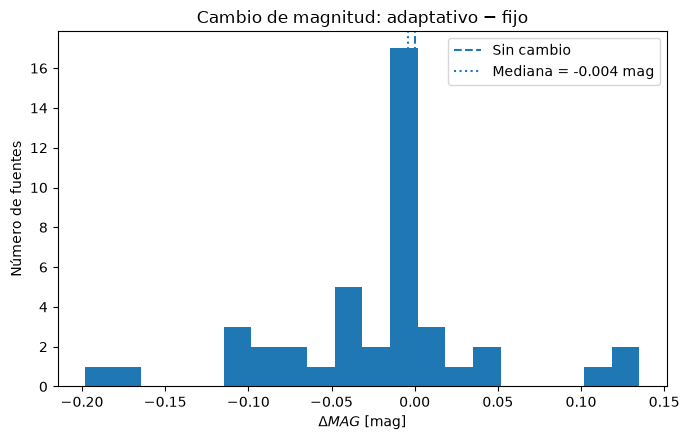

In [84]:
plt.figure(figsize=(7, 4.5))

plt.hist(
    adaptadas_validas["delta_mag"],
    bins=20
)

plt.axvline(
    0,
    linestyle="--",
    label="Sin cambio"
)

plt.axvline(
    np.median(adaptadas_validas["delta_mag"]),
    linestyle=":",
    label=rf"Mediana = {np.median(adaptadas_validas['delta_mag']):.3f} mag"
)

plt.xlabel(r"$\Delta MAG$ [mag]")
plt.ylabel("Número de fuentes")
plt.title("Cambio de magnitud: adaptativo − fijo")
plt.legend()
plt.tight_layout()
plt.show()


### Comparación entre fotometría fija y adaptativa para V · Chip 1

La comparación fotométrica se realizó sobre las \(43\) fuentes cuyo anillo inicial fue clasificado como contaminado y para las cuales el procedimiento adaptativo encontró una posición alternativa aceptable.

La prueba de control realizada previamente demostró que, cuando la geometría del anillo permanece sin cambios, las dos ejecuciones de `PHOT` producen resultados idénticos. Por lo tanto, las diferencias observadas en estas \(43\) fuentes están asociadas al cambio en la región utilizada para estimar el cielo.

La mediana del cambio en el nivel de cielo fue:

$$
\boxed{
\mathrm{mediana}(\Delta MSKY)
=
-0.1653\ \mathrm{ADU}
}
$$

donde:

$$
\Delta MSKY
=
MSKY_{\mathrm{adapt}}
-
MSKY_{\mathrm{fixed}}.
$$

El valor negativo indica que, para la muestra analizada, el anillo adaptativo tiende a estimar un nivel de cielo ligeramente menor.

La dispersión del cielo también presentó una disminución:

$$
\boxed{
\mathrm{mediana}(\Delta STDEV)
=
-0.0641\ \mathrm{ADU}
}
$$

lo cual indica una reducción moderada en la dispersión de los píxeles utilizados para estimar el fondo.

### Efecto sobre la magnitud y el flujo

La diferencia de magnitud se definió como:

$$
\Delta MAG
=
MAG_{\mathrm{adapt}}
-
MAG_{\mathrm{fixed}}.
$$

Para las \(43\) fuentes analizadas se obtuvo:

$$
\boxed{
\mathrm{mediana}(\Delta MAG)
=
-0.004\ \mathrm{mag}
}
$$

mientras que la mediana del valor absoluto de la diferencia fue:

$$
\boxed{
\mathrm{mediana}(|\Delta MAG|)
=
0.019\ \mathrm{mag}
}
$$

La dispersión robusta de las diferencias, estimada mediante la desviación absoluta mediana, fue:

$$
\boxed{
\sigma_{\mathrm{MAD}}(\Delta MAG)
=
0.0282\ \mathrm{mag}
}
$$

La razón entre el flujo medido con el anillo adaptativo y el flujo obtenido con el anillo fijo presentó una mediana de:

$$
\boxed{
\mathrm{mediana}
\left(
\frac{FLUX_{\mathrm{adapt}}}
{FLUX_{\mathrm{fixed}}}
\right)
=
1.00363
}
$$

Esto corresponde a un incremento mediano del flujo de aproximadamente:

$$
(1.00363-1)\times100
\approx0.36\%.
$$

Los cambios en magnitud y flujo son pequeños, lo cual indica que el desplazamiento del anillo no introduce modificaciones fotométricas grandes en la muestra analizada.

### Efecto sobre el error fotométrico y la razón señal a ruido

La mediana del error fotométrico obtenido con el anillo fijo fue:

$$
MERR_{\mathrm{fixed,med}}
=
0.031\ \mathrm{mag}.
$$

Con el anillo adaptativo se obtuvo:

$$
MERR_{\mathrm{adapt,med}}
=
0.029\ \mathrm{mag}.
$$

Por lo tanto, el error fotométrico mediano disminuyó ligeramente después de modificar la región utilizada para estimar el cielo.

De las \(43\) fuentes analizadas:

$$
24
$$

presentaron un valor de `MERR` menor con el anillo adaptativo.

Esto representa:

$$
\frac{24}{43}\times100
=
55.81\%.
$$

Por tanto:

$$
\boxed{55.81\%}
$$

de las fuentes recuperadas presentaron una reducción individual del error fotométrico.

La razón señal a ruido aproximada presentó una mediana de:

$$
(S/N)_{\mathrm{fixed}}
=
35.02
$$

para la fotometría fija y:

$$
(S/N)_{\mathrm{adapt}}
=
37.44
$$

para la fotometría adaptativa.

Esto representa un incremento aproximado de:

$$
\frac{37.44-35.02}{35.02}\times100
\approx6.9\%.
$$

### Interpretación preliminar de V · Chip 1

Los resultados obtenidos muestran que el procedimiento adaptativo logra modificar la región de cielo de las fuentes identificadas como contaminadas sin producir cambios grandes en las magnitudes medidas.

Para las \(43\) fuentes recuperadas se observa, en mediana:

$$
\Delta MSKY<0
$$

y:

$$
\Delta STDEV<0,
$$

lo que indica que las nuevas regiones seleccionadas presentan un nivel de fondo ligeramente menor y una dispersión menor que los anillos originales.

Al mismo tiempo, la magnitud presenta un cambio mediano pequeño:

$$
\Delta MAG=-0.004\ \mathrm{mag},
$$

mientras que el flujo aumenta aproximadamente un \(0.36\%\).

El error fotométrico mediano disminuye de:

$$
0.031\ \mathrm{mag}
$$

a:

$$
0.029\ \mathrm{mag},
$$

y la razón señal a ruido mediana aumenta de aproximadamente:

$$
35.02
$$

a:

$$
37.44.
$$

Estos resultados constituyen evidencia favorable sobre la estabilidad interna del procedimiento adaptativo para V · Chip 1. Sin embargo, no constituyen por sí solos una medición de exactitud absoluta, ya que no se dispone en esta comparación de un flujo verdadero externo para cada fuente.

In [85]:
n = len(adaptadas_validas)

n_msky_menor = (
    adaptadas_validas["delta_msky"] < 0
).sum()

n_stdev_menor = (
    adaptadas_validas["delta_stdev"] < 0
).sum()

n_mag_neg = (
    adaptadas_validas["delta_mag"] < 0
).sum()

n_flux_mayor = (
    adaptadas_validas["flux_ratio"] > 1
).sum()

n_snr_mayor = (
    adaptadas_validas["snr_adapt"]
    > adaptadas_validas["snr_fixed"]
).sum()

print("Total:", n)

print()
print(
    "MSKY menor:",
    n_msky_menor,
    f"({100*n_msky_menor/n:.2f}%)"
)

print(
    "STDEV menor:",
    n_stdev_menor,
    f"({100*n_stdev_menor/n:.2f}%)"
)

print(
    "MAG menor (más brillante):",
    n_mag_neg,
    f"({100*n_mag_neg/n:.2f}%)"
)

print(
    "FLUX mayor:",
    n_flux_mayor,
    f"({100*n_flux_mayor/n:.2f}%)"
)

print(
    "S/N mayor:",
    n_snr_mayor,
    f"({100*n_snr_mayor/n:.2f}%)"
)

Total: 43

MSKY menor: 33 (76.74%)
STDEV menor: 33 (76.74%)
MAG menor (más brillante): 31 (72.09%)
FLUX mayor: 33 (76.74%)
S/N mayor: 24 (55.81%)


In [86]:
# f_out original del anillo fijo
fout_inicial = df_anillos[
    ["x", "y", "f_out"]
].rename(
    columns={"f_out": "f_out_inicial"}
)

# f_out seleccionado por el procedimiento adaptativo
fout_final = df_adapt[
    (df_adapt["estado"] == "aceptado") &
    (df_adapt["r_in"] > 22.55)
][
    ["x", "y", "r_in", "r_out", "f_out"]
].rename(
    columns={"f_out": "f_out_final"}
)

comparacion_fout = fout_final.merge(
    fout_inicial,
    on=["x", "y"],
    how="left"
)

comparacion_fout["delta_f_out"] = (
    comparacion_fout["f_out_final"]
    - comparacion_fout["f_out_inicial"]
)

print("Fuentes recuperadas:", len(comparacion_fout))

print()
print(
    "Mediana f_out inicial:",
    np.median(comparacion_fout["f_out_inicial"])
)

print(
    "Mediana f_out final:",
    np.median(comparacion_fout["f_out_final"])
)

print(
    "Mediana Δf_out:",
    np.median(comparacion_fout["delta_f_out"])
)

print(
    "Todas reducen f_out:",
    (comparacion_fout["delta_f_out"] < 0).all()
)

print()
print(
    "Reducción mediana en puntos porcentuales:",
    -100 * np.median(comparacion_fout["delta_f_out"])
)

Fuentes recuperadas: 43

Mediana f_out inicial: 0.045118082481494536
Mediana f_out final: 0.013437057991513438
Mediana Δf_out: -0.028888406527872525
Todas reducen f_out: True

Reducción mediana en puntos porcentuales: 2.8888406527872523


**### Visualización de la reducción de contaminación**

Cada punto representa una de las fuentes recuperadas. La diagonal corresponde al caso en que el anillo adaptativo no modifica \(f_{\mathrm{out}}\). Los puntos por debajo de la diagonal presentan una reducción de la contaminación.


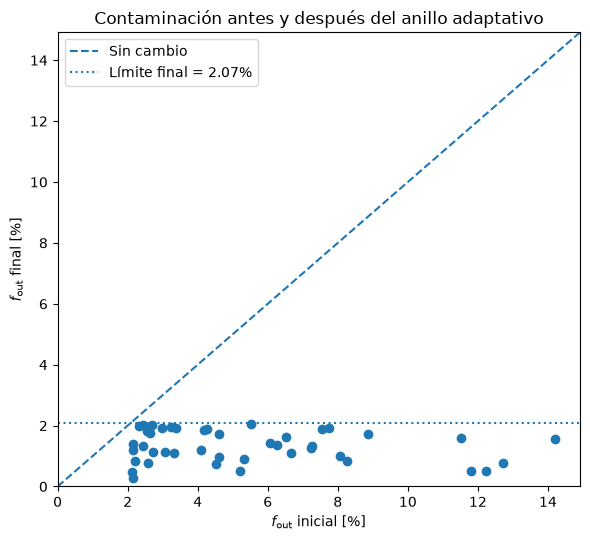

In [87]:
x_fout = comparacion_fout["f_out_inicial"] * 100
y_fout = comparacion_fout["f_out_final"] * 100

lim_fout = max(
    x_fout.max(),
    y_fout.max()
) * 1.05

plt.figure(figsize=(6, 5.5))

plt.scatter(
    x_fout,
    y_fout
)

plt.plot(
    [0, lim_fout],
    [0, lim_fout],
    linestyle="--",
    label="Sin cambio"
)

plt.axhline(
    f_lim * 100,
    linestyle=":",
    label=f"Límite final = {f_lim*100:.2f}%"
)

plt.xlabel(r"$f_{\mathrm{out}}$ inicial [%]")
plt.ylabel(r"$f_{\mathrm{out}}$ final [%]")
plt.title("Contaminación antes y después del anillo adaptativo")
plt.xlim(0, lim_fout)
plt.ylim(0, lim_fout)
plt.legend()
plt.tight_layout()
plt.show()


### Verificación de la reducción de contaminación para V · Chip 1

Para evaluar directamente el objetivo del procedimiento adaptativo se comparó el valor de:

$$
f_{\mathrm{out}}
$$

antes y después de desplazar el anillo para las \(43\) fuentes recuperadas.

La mediana inicial de la fracción de píxeles anormalmente altos fue:

$$
\mathrm{mediana}(f_{\mathrm{out,initial}})
=
0.045118
$$

equivalente aproximadamente a:

$$
4.51\%.
$$

Después de seleccionar adaptativamente una nueva región de cielo, la mediana fue:

$$
\mathrm{mediana}(f_{\mathrm{out,final}})
=
0.013437
$$

equivalente aproximadamente a:

$$
1.34\%.
$$

Para cada fuente se definió:

$$
\Delta f_{\mathrm{out}}
=
f_{\mathrm{out,final}}
-
f_{\mathrm{out,initial}}.
$$

La mediana de esta diferencia fue:

$$
\boxed{
\mathrm{mediana}(\Delta f_{\mathrm{out}})
=
-0.02889
}
$$

lo cual corresponde a una reducción individual mediana de aproximadamente:

$$
\boxed{2.89\ \text{puntos porcentuales}}.
$$

Las \(43\) fuentes recuperadas presentaron:

$$
\Delta f_{\mathrm{out}}<0.
$$

Por tanto:

$$
\boxed{43/43}
$$

fuentes redujeron la fracción de píxeles contaminantes después de desplazar el anillo.

Este resultado confirma que el procedimiento cumple su objetivo operacional de seleccionar regiones de cielo con menor contaminación según el indicador definido.

### Comportamiento individual de los parámetros fotométricos

Además de estudiar las medianas globales, se analizó cuántas de las \(43\) fuentes recuperadas presentaron cambios favorables en cada parámetro fotométrico.

El nivel de cielo estimado disminuyó en:

$$
33/43
$$

fuentes, correspondientes a:

$$
\boxed{76.74\%}.
$$

La dispersión del cielo también disminuyó en:

$$
33/43
$$

fuentes:

$$
\boxed{76.74\%}.
$$

La magnitud obtenida con el anillo adaptativo fue menor, es decir, la fuente resultó ligeramente más brillante, en:

$$
31/43
$$

casos:

$$
\boxed{72.09\%}.
$$

El flujo medido aumentó en:

$$
33/43
$$

fuentes:

$$
\boxed{76.74\%}.
$$

Finalmente, la razón señal a ruido aumentó en:

$$
24/43
$$

fuentes:

$$
\boxed{55.81\%}.
$$

Estos resultados muestran que la reducción del indicador de contaminación no implica necesariamente una mejora simultánea de todos los parámetros para cada fuente. Sin embargo, la mayoría de las fuentes recuperadas presentan un nivel de cielo menor, una menor dispersión del fondo y un flujo ligeramente superior.

### Conclusión preliminar de V · Chip 1

El procesamiento completo del chip 1 del filtro V permitió evaluar el comportamiento del procedimiento adaptativo sobre una muestra real.

A partir de \(385\) fuentes aisladas, el anillo fijo fue clasificado como limpio para:

$$
323
$$

fuentes y como contaminado para:

$$
62.
$$

El algoritmo adaptativo encontró una región alternativa aceptable para:

$$
43
$$

de las \(62\) fuentes inicialmente contaminadas, obteniéndose una tasa de recuperación de:

$$
\boxed{69.35\%}.
$$

En consecuencia, el número total de fuentes con un anillo aceptable aumentó de:

$$
323
$$

a:

$$
366,
$$

equivalente al:

$$
\boxed{95.06\%}
$$

de las \(385\) fuentes analizadas.

Para las \(43\) fuentes recuperadas, todas presentaron una reducción del indicador de contaminación:

$$
\boxed{\Delta f_{\mathrm{out}}<0}.
$$

La reducción individual mediana fue aproximadamente:

$$
\boxed{2.89\ \text{puntos porcentuales}}.
$$

Adicionalmente, el \(76.74\%\) de las fuentes presentó una disminución del nivel de cielo y el mismo porcentaje presentó una disminución de la dispersión del fondo.

La diferencia mediana de magnitud fue pequeña:

$$
\boxed{\Delta MAG=-0.004\ \mathrm{mag}},
$$

mientras que la mediana del valor absoluto de la diferencia fue:

$$
\boxed{|\Delta MAG|_{\mathrm{med}}=0.019\ \mathrm{mag}}.
$$

El error fotométrico mediano disminuyó de:

$$
0.031\ \mathrm{mag}
$$

a:

$$
0.029\ \mathrm{mag},
$$

y la razón señal a ruido mediana aumentó de:

$$
35.02
$$

a:

$$
37.44.
$$

Los resultados de V · Chip 1 muestran que el procedimiento adaptativo es efectivo para reducir el indicador de contaminación utilizado para seleccionar el cielo. Los cambios fotométricos observados son pequeños y generalmente consistentes con una estimación de fondo ligeramente menor y menos dispersa.

Estos resultados constituyen una validación interna favorable del método para este chip, pero no representan todavía una medida de exactitud fotométrica absoluta. La evaluación deberá repetirse sobre los demás chips para determinar si el comportamiento se mantiene en diferentes regiones del detector.

In [88]:
resumen_v_chip1 = pd.DataFrame({
    "parametro": [
        "FWHM_pix",
        "sigma_sky_ADU",
        "threshold",
        "N_daofind",
        "N_phot_ready",
        "N_phot_validas",
        "N_MERR_020",
        "N_aisladas",
        "N_anillo_fijo_limpio",
        "N_anillo_fijo_contaminado",
        "N_adapt_recuperadas",
        "N_adapt_sin_solucion",
        "porcentaje_recuperacion",
        "f_lim",
        "mediana_fout_inicial_recuperadas",
        "mediana_fout_final_recuperadas",
        "mediana_delta_fout",
        "mediana_delta_mag",
        "mediana_delta_msky",
        "mediana_delta_stdev"
    ],
    "valor": [
        4.51,
        3.16,
        3.55,
        11819,
        8327,
        5047,
        745,
        385,
        323,
        62,
        43,
        19,
        69.35,
        0.020698,
        0.045118,
        0.013437,
        -0.028888,
        -0.004,
        -0.165301,
        -0.064087
    ]
})

resumen_v_chip1

,parametro,valor
0,FWHM_pix,4.510000
1,sigma_sky_ADU,3.160000
2,threshold,3.550000
3,N_daofind,11819.000000
4,N_phot_ready,8327.000000
5,N_phot_validas,5047.000000
6,N_MERR_020,745.000000
7,N_aisladas,385.000000
8,N_anillo_fijo_limpio,323.000000
9,N_anillo_fijo_contaminado,62.000000


**### Resumen visual del procesamiento de V · Chip 1**

La gráfica final resume el número de fuentes que permanece en cada etapa principal del procesamiento. La última etapa aumenta respecto al número de anillos fijos limpios porque el método adaptativo recupera parte de las fuentes inicialmente contaminadas.


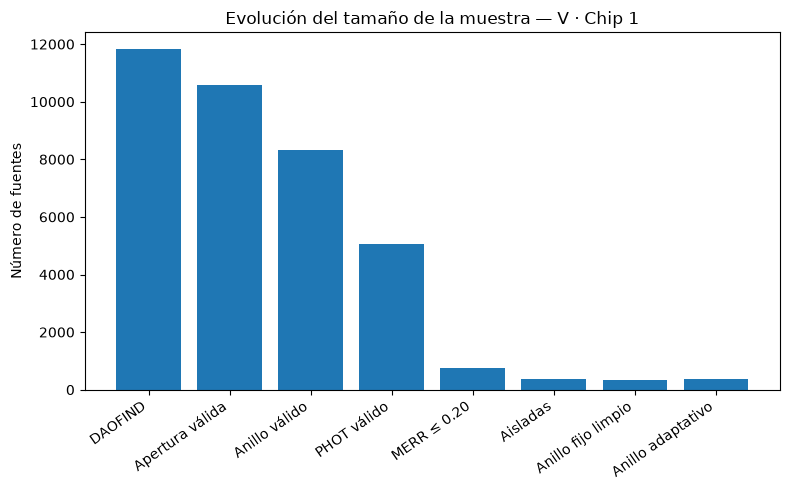

In [89]:
etapas = [
    "DAOFIND",
    "Apertura válida",
    "Anillo válido",
    "PHOT válido",
    "MERR ≤ 0.20",
    "Aisladas",
    "Anillo fijo limpio",
    "Anillo adaptativo"
]

conteos = [
    11819,
    10593,
    8327,
    5047,
    745,
    385,
    323,
    366
]

plt.figure(figsize=(8, 5))

plt.bar(
    etapas,
    conteos
)

plt.ylabel("Número de fuentes")
plt.title("Evolución del tamaño de la muestra — V · Chip 1")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


**## Automatización del procesamiento para los siguientes chips**

El procesamiento de **V · Chip 1** se conserva como caso de referencia y validación del procedimiento completo.

A partir de los siguientes chips se utilizará un esquema **semiautomático**. Las dos etapas que permanecen supervisadas manualmente son:

1. La selección de estrellas adecuadas para determinar el \(FWHM\).
2. La selección de regiones visualmente vacías para estimar la dispersión del cielo.

Una vez obtenidos estos valores, las etapas posteriores se ejecutarán mediante funciones reutilizables para mantener los mismos criterios en todos los chips.

El flujo general será:

$$
FWHM
\rightarrow
\sigma_{\mathrm{sky}}
\rightarrow
threshold
\rightarrow
DAOFIND
\rightarrow
\text{limpieza geométrica}
\rightarrow
PHOT
\rightarrow
MERR
\rightarrow
\text{vecinos}
\rightarrow
f_{\mathrm{out}}
\rightarrow
\text{anillo adaptativo}.
$$

Esta automatización reduce la intervención manual y permite aplicar exactamente los mismos criterios metodológicos a los ocho chips.

**### Librerías y configuración general**

Las siguientes funciones se utilizarán para procesar cualquier chip cambiando únicamente el número de chip, el filtro y las mediciones iniciales de \(FWHM\) y cielo.

In [90]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from scipy.ndimage import distance_transform_edt
from scipy.spatial import cKDTree

# Ruta principal del proyecto en el Mac
BASE = (
    Path.home()
    / "Desktop"
    / "Universidad"
    / "tesis"
    / "dataSextansA"
)

THRESHOLDS_DEFAULT = np.array([
    2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0
])

MERR_MAX_DEFAULT = 0.20
ANCHO_SKY_DEFAULT = 15.0
PASO_ANILLO_DEFAULT = 5.0
N_ANILLOS_DEFAULT = 5
VALOR_INVALIDO_DEFAULT = 50000.0

**### Funciones para FWHM y cielo**

Estas funciones reciben las mediciones supervisadas realizadas con `imexamine` y calculan automáticamente los estadísticos adoptados.

In [91]:
def resumir_fwhm(valores, mostrar=True):
    """
    Calcula los estadísticos del FWHM a partir de las estrellas
    que ya fueron seleccionadas manualmente como adecuadas.
    """
    valores = np.asarray(valores, dtype=float)
    valores = valores[np.isfinite(valores)]

    if len(valores) == 0:
        raise ValueError("No hay valores válidos de FWHM.")

    resultado = {
        "n": len(valores),
        "mediana": float(np.median(valores)),
        "media": float(np.mean(valores)),
        "std": float(np.std(valores, ddof=1)) if len(valores) > 1 else np.nan,
    }

    resultado["r_ap"] = 3.0 * resultado["mediana"]
    resultado["r_sky_in"] = 5.0 * resultado["mediana"]
    resultado["r_sky_out"] = (
        resultado["r_sky_in"] + ANCHO_SKY_DEFAULT
    )

    if mostrar:
        print(f"N estrellas        = {resultado['n']}")
        print(f"FWHM mediano       = {resultado['mediana']:.4f} pix")
        print(f"FWHM medio         = {resultado['media']:.4f} pix")
        print(f"Desv. estándar     = {resultado['std']:.4f} pix")
        print(f"Radio apertura     = {resultado['r_ap']:.4f} pix")
        print(f"Radio sky interno  = {resultado['r_sky_in']:.4f} pix")
        print(f"Radio sky externo  = {resultado['r_sky_out']:.4f} pix")

    return resultado


def resumir_cielo(sigmas, medianas=None, mostrar=True):
    """
    Aplica Tukey a la distribución de sigma de las cajas de cielo.
    Devuelve sigma_sky como la mediana de las cajas aceptadas.
    """
    sigmas = np.asarray(sigmas, dtype=float)
    sigmas = sigmas[np.isfinite(sigmas)]

    if len(sigmas) == 0:
        raise ValueError("No hay mediciones válidas de sigma del cielo.")

    q1 = np.percentile(sigmas, 25)
    q3 = np.percentile(sigmas, 75)
    iqr = q3 - q1
    limite = q3 + 1.5 * iqr

    mask = sigmas <= limite
    aceptadas = sigmas[mask]
    rechazadas = sigmas[~mask]

    resultado = {
        "q1": float(q1),
        "q3": float(q3),
        "iqr": float(iqr),
        "limite": float(limite),
        "n_total": len(sigmas),
        "n_aceptadas": len(aceptadas),
        "n_rechazadas": len(rechazadas),
        "sigma_sky": float(np.median(aceptadas)),
        "aceptadas": aceptadas,
        "rechazadas": rechazadas,
    }

    if medianas is not None:
        med = np.asarray(medianas, dtype=float)
        med = med[np.isfinite(med)]
        if len(med):
            resultado["sky_mediana"] = float(np.median(med))

    if mostrar:
        print(f"Q1                 = {q1:.4f} ADU")
        print(f"Q3                 = {q3:.4f} ADU")
        print(f"IQR                = {iqr:.4f} ADU")
        print(f"Límite Tukey       = {limite:.4f} ADU")
        print(f"Cajas aceptadas    = {len(aceptadas)}")
        print(f"Cajas rechazadas   = {len(rechazadas)}")
        print(f"Sigma sky adoptado = {resultado['sigma_sky']:.4f} ADU")
        if "sky_mediana" in resultado:
            print(f"Mediana del cielo  = {resultado['sky_mediana']:.4f} ADU")

    return resultado

**### Automatización de las pruebas de `DAOFIND`**

La siguiente función genera un archivo `.cl` que ejecuta todas las pruebas de `threshold` con los mismos parámetros utilizados en el chip 1.

Después de medir \(FWHM\) y \(\sigma_{\mathrm{sky}}\), solamente será necesario ejecutar el archivo generado desde IRAF.

In [92]:
def rutas_chip(chip, filtro="V", base=BASE):
    chip = int(chip)
    carpeta = base / "chips" / f"chip{chip}"

    return {
        "carpeta": carpeta,
        "imagen": carpeta / f"SexA_{filtro}_chip{chip}.fits",
        "prefijo": f"{filtro}_chip{chip}",
    }


def generar_script_daofind(
    chip,
    filtro,
    fwhm,
    sigma_sky,
    thresholds=THRESHOLDS_DEFAULT,
    base=BASE,
):
    rutas = rutas_chip(chip, filtro, base)
    carpeta = rutas["carpeta"]
    imagen = rutas["imagen"]
    prefijo = rutas["prefijo"]

    hdr = fits.getheader(imagen)

    gain = hdr.get("GAIN", 2.75)
    rdnoise = hdr.get("RDNOISE", 6.4125)
    saturate = hdr.get("SATURATE", 39000)

    lineas = [
        f'datapars.fwhmpsf = {fwhm:.6f}',
        f'datapars.sigma = {sigma_sky:.6f}',
        'datapars.datamin = INDEF',
        f'datapars.datamax = {saturate}',
        f'datapars.readnoise = {rdnoise}',
        f'datapars.epadu = {gain}',
        '',
    ]

    for th in thresholds:
        tag = str(th).replace(".", "_")
        salida = carpeta / f"{prefijo}_thr{tag}.coo"

        lineas += [
            f'findpars.threshold = {th}',
            (
                f'daofind {imagen} '
                f'output={salida} verify-'
            ),
            '',
        ]

    script = carpeta / f"{prefijo}_daofind.cl"
    script.write_text("\n".join(lineas), encoding="utf-8")

    print("Script creado:")
    print(script)
    print()
    print("Ejecutar dentro de IRAF:")
    print(f"cl < {script}")

    return script

**### Cálculo automático del threshold**

Una vez obtenidos los conteos de `DAOFIND`, la siguiente función ajusta:

$$
\ln N=ax^2+bx+c
$$

y calcula el valor donde:

$$
\frac{d\ln N}{dx}=-1.
$$

También genera automáticamente las gráficas utilizadas para visualizar el comportamiento de las detecciones.

In [93]:
def analizar_threshold(thresholds, detecciones, graficar=True):
    thresholds = np.asarray(thresholds, dtype=float)
    detecciones = np.asarray(detecciones, dtype=float)

    if len(thresholds) != len(detecciones):
        raise ValueError("thresholds y detecciones deben tener igual longitud.")

    if np.any(detecciones <= 0):
        raise ValueError("Todos los conteos deben ser positivos.")

    lnN = np.log(detecciones)

    a, b, c = np.polyfit(thresholds, lnN, 2)
    ajuste = np.polyval([a, b, c], thresholds)

    ss_res = np.sum((lnN - ajuste) ** 2)
    ss_tot = np.sum((lnN - np.mean(lnN)) ** 2)
    r2 = 1 - ss_res / ss_tot

    threshold_opt = (-1 - b) / (2 * a)

    tabla = pd.DataFrame({
        "threshold": thresholds,
        "detecciones": detecciones.astype(int),
        "lnN": lnN,
    })

    resultado = {
        "a": float(a),
        "b": float(b),
        "c": float(c),
        "r2": float(r2),
        "threshold_optimo": float(threshold_opt),
        "tabla": tabla,
    }

    print(
        f"ln(N) = {a:.8f} x² "
        f"{b:+.8f} x {c:+.8f}"
    )
    print(f"R² = {r2:.8f}")
    print(f"Threshold calculado = {threshold_opt:.4f}")

    if graficar:
        plt.figure(figsize=(7, 4.5))
        plt.plot(thresholds, detecciones, marker="o")
        plt.axvline(
            threshold_opt,
            linestyle="--",
            label=f"Threshold = {threshold_opt:.2f}"
        )
        plt.xlabel("Threshold [σ]")
        plt.ylabel("Número de detecciones")
        plt.title("DAOFIND: detecciones vs. threshold")
        plt.legend()
        plt.tight_layout()
        plt.show()

        xgrid = np.linspace(
            thresholds.min(),
            thresholds.max(),
            300
        )

        plt.figure(figsize=(7, 4.5))
        plt.scatter(thresholds, lnN, label="Datos")
        plt.plot(
            xgrid,
            np.polyval([a, b, c], xgrid),
            label="Ajuste cuadrático"
        )
        plt.axvline(
            threshold_opt,
            linestyle="--",
            label=f"Threshold = {threshold_opt:.2f}"
        )
        plt.xlabel("Threshold [σ]")
        plt.ylabel(r"$\ln(N)$")
        plt.title(r"Ajuste de $\ln(N)$ vs. threshold")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return resultado

**### Lectura y limpieza del catálogo de `DAOFIND`**

La limpieza geométrica se aplica automáticamente utilizando la distancia al píxel de relleno más cercano y la distancia al borde del chip.

In [94]:
def cargar_daofind(archivo):
    columnas = [
        "x",
        "y",
        "mag_daofind",
        "sharpness",
        "sround",
        "ground",
        "id",
    ]

    return pd.read_csv(
        archivo,
        comment="#",
        sep=r"\s+",
        names=columnas,
        engine="python",
    )


def agregar_distancias_geometricas(
    imagen_path,
    catalogo,
    valor_invalido=VALOR_INVALIDO_DEFAULT,
):
    imagen = fits.getdata(imagen_path).astype(float)
    ny, nx = imagen.shape

    mask_invalidos = imagen == valor_invalido
    dist_invalidos = distance_transform_edt(~mask_invalidos)

    resultado = catalogo.copy()

    xpix = np.rint(resultado["x"]).astype(int).to_numpy() - 1
    ypix = np.rint(resultado["y"]).astype(int).to_numpy() - 1

    dentro = (
        (xpix >= 0) &
        (xpix < nx) &
        (ypix >= 0) &
        (ypix < ny)
    )

    d_invalidos = np.full(len(resultado), np.nan)

    d_invalidos[dentro] = dist_invalidos[
        ypix[dentro],
        xpix[dentro],
    ]

    x = resultado["x"].to_numpy()
    y = resultado["y"].to_numpy()

    d_borde = np.minimum.reduce([
        x - 1,
        nx - x,
        y - 1,
        ny - y,
    ])

    resultado["dist_invalidos"] = d_invalidos
    resultado["dist_borde"] = d_borde

    return resultado, imagen


def filtrar_distancia(catalogo, distancia):
    mask = (
        catalogo["dist_invalidos"].gt(distancia) &
        catalogo["dist_borde"].gt(distancia)
    )

    return (
        catalogo[mask].copy(),
        catalogo[~mask].copy(),
    )

**### Lectura de `PHOT`, calidad fotométrica y vecinos**

Estas funciones aplican los mismos criterios utilizados en V · Chip 1:

$$
MERR\leq0.20\ \mathrm{mag}
$$

y:

$$
d_{\mathrm{vecino}}>r_{\mathrm{ap}}.
$$

In [95]:
def cargar_phot(archivo):
    columnas = [
        "x",
        "y",
        "msky",
        "stdev",
        "nsky",
        "flux",
        "mag",
        "merr",
    ]

    return pd.read_csv(
        archivo,
        sep=r"\s+",
        names=columnas,
        na_values="INDEF",
    )


def seleccionar_calidad(df_phot, merr_max=MERR_MAX_DEFAULT):
    validas = df_phot[
        df_phot["mag"].notna() &
        df_phot["merr"].notna()
    ].copy()

    calidad = validas[
        validas["merr"] <= merr_max
    ].copy()

    return validas, calidad


def filtrar_vecinos(df_calidad, catalogo_daofind, d_crit):
    targets = df_calidad[["x", "y"]].to_numpy()
    pool = catalogo_daofind[["x", "y"]].to_numpy()

    tree = cKDTree(pool)

    distancias, _ = tree.query(targets, k=2)

    d_match = distancias[:, 0]
    d_vecino = distancias[:, 1]

    resultado = df_calidad.copy()
    resultado["d_vecino"] = d_vecino

    mask = resultado["d_vecino"] > d_crit

    aisladas = resultado[mask].copy()
    rechazadas = resultado[~mask].copy()

    print(f"Máx. distancia match propio = {d_match.max():.6f}")
    print(f"Mediana distancia vecino    = {np.median(d_vecino):.4f} pix")
    print(f"Aisladas                    = {len(aisladas)}")
    print(f"Rechazadas por vecino       = {len(rechazadas)}")

    return aisladas, rechazadas

**### Funciones para contaminación del anillo y selección adaptativa**

La primera regla de Tukey identifica píxeles altos dentro de cada anillo. La segunda regla de Tukey se aplica sobre la distribución de \(f_{\mathrm{out}}\) entre las estrellas aisladas.

In [96]:
def evaluar_anillo(
    imagen,
    x_iraf,
    y_iraf,
    r_in,
    r_out,
    valor_invalido=VALOR_INVALIDO_DEFAULT,
):
    ny, nx = imagen.shape

    x = float(x_iraf) - 1
    y = float(y_iraf) - 1

    if (
        x - r_out < 0 or
        x + r_out >= nx or
        y - r_out < 0 or
        y + r_out >= ny
    ):
        return None

    xmin = int(np.floor(x - r_out))
    xmax = int(np.ceil(x + r_out)) + 1
    ymin = int(np.floor(y - r_out))
    ymax = int(np.ceil(y + r_out)) + 1

    sub = imagen[ymin:ymax, xmin:xmax]

    yy, xx = np.indices(sub.shape)

    xxg = xx + xmin
    yyg = yy + ymin

    r = np.sqrt(
        (xxg - x) ** 2 +
        (yyg - y) ** 2
    )

    mask = (r >= r_in) & (r <= r_out)
    valores = sub[mask]

    if np.any(valores == valor_invalido):
        return None

    valores = valores[np.isfinite(valores)]

    if len(valores) == 0:
        return None

    q1 = np.percentile(valores, 25)
    q3 = np.percentile(valores, 75)
    iqr = q3 - q1
    limite = q3 + 1.5 * iqr

    n_sky = len(valores)
    n_out = int(np.sum(valores > limite))
    f_out = n_out / n_sky

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "limite_alto": limite,
        "N_sky": n_sky,
        "N_out": n_out,
        "f_out": f_out,
    }


def analizar_anillo_fijo(
    imagen,
    df_aisladas,
    r_in,
    ancho=ANCHO_SKY_DEFAULT,
):
    r_out = r_in + ancho

    filas = []

    for _, estrella in df_aisladas.iterrows():
        res = evaluar_anillo(
            imagen,
            estrella["x"],
            estrella["y"],
            r_in,
            r_out,
        )

        if res is None:
            continue

        filas.append({
            "x": estrella["x"],
            "y": estrella["y"],
            **res,
        })

    df_anillos = pd.DataFrame(filas)

    f = df_anillos["f_out"].to_numpy()

    q1 = np.percentile(f, 25)
    q3 = np.percentile(f, 75)
    iqr = q3 - q1
    f_lim = q3 + 1.5 * iqr

    df_limpio = df_anillos[
        df_anillos["f_out"] <= f_lim
    ].copy()

    df_contaminado = df_anillos[
        df_anillos["f_out"] > f_lim
    ].copy()

    print(f"Total analizadas = {len(df_anillos)}")
    print(f"f_lim             = {f_lim:.6f} ({100*f_lim:.2f}%)")
    print(f"Cielo limpio      = {len(df_limpio)}")
    print(f"Contaminadas      = {len(df_contaminado)}")

    return df_anillos, df_limpio, df_contaminado, float(f_lim)


def seleccionar_anillo_adaptativo(
    imagen,
    df_aisladas,
    f_lim,
    r_inicial,
    ancho=ANCHO_SKY_DEFAULT,
    paso=PASO_ANILLO_DEFAULT,
    n_anillos=N_ANILLOS_DEFAULT,
):
    radios = [
        (
            r_inicial + i * paso,
            r_inicial + i * paso + ancho,
        )
        for i in range(n_anillos)
    ]

    filas = []

    for _, estrella in df_aisladas.iterrows():
        x = estrella["x"]
        y = estrella["y"]

        solucion = None
        hubo_valido = False

        for r_in, r_out in radios:
            res = evaluar_anillo(
                imagen,
                x,
                y,
                r_in,
                r_out,
            )

            if res is None:
                continue

            hubo_valido = True

            if res["f_out"] <= f_lim:
                solucion = {
                    "x": x,
                    "y": y,
                    "r_in": r_in,
                    "r_out": r_out,
                    "f_out": res["f_out"],
                    "N_sky": res["N_sky"],
                    "N_out": res["N_out"],
                    "estado": "aceptado",
                }
                break

        if solucion is None:
            solucion = {
                "x": x,
                "y": y,
                "r_in": np.nan,
                "r_out": np.nan,
                "f_out": np.nan,
                "N_sky": np.nan,
                "N_out": np.nan,
                "estado": (
                    "contaminado_hasta_rmax"
                    if hubo_valido
                    else "sin_solucion_geometrica"
                ),
            }

        filas.append(solucion)

    return pd.DataFrame(filas)

**### Creación automática de grupos y script de `PHOT` adaptativo**

Las fuentes aceptadas se separan automáticamente según el anillo seleccionado. Después se genera un script de IRAF con una ejecución de `PHOT` para cada grupo.

In [97]:
def crear_grupos_adaptativos(
    df_adapt,
    chip,
    filtro,
    base=BASE,
):
    rutas = rutas_chip(chip, filtro, base)
    carpeta = rutas["carpeta"]
    prefijo = rutas["prefijo"]

    aceptadas = df_adapt[
        df_adapt["estado"] == "aceptado"
    ].copy()

    grupos = []

    for (r_in, r_out), grupo in aceptadas.groupby(
        ["r_in", "r_out"]
    ):
        tag = (
            f"r{r_in:.2f}_{r_out:.2f}"
            .replace(".", "_")
        )

        archivo = carpeta / f"{prefijo}_adapt_{tag}.coo"

        grupo[["x", "y"]].to_csv(
            archivo,
            sep=" ",
            index=False,
            header=False,
            float_format="%.3f",
        )

        grupos.append({
            "r_in": r_in,
            "r_out": r_out,
            "n": len(grupo),
            "coords": archivo,
            "tag": tag,
        })

    tabla = pd.DataFrame(grupos)

    print(tabla[["r_in", "r_out", "n"]])

    return tabla


def generar_script_phot_adaptativo(
    chip,
    filtro,
    tabla_grupos,
    fwhm,
    sigma_sky,
    base=BASE,
):
    rutas = rutas_chip(chip, filtro, base)
    carpeta = rutas["carpeta"]
    imagen = rutas["imagen"]
    prefijo = rutas["prefijo"]

    hdr = fits.getheader(imagen)

    gain = hdr.get("GAIN", 2.75)
    rdnoise = hdr.get("RDNOISE", 6.4125)
    saturate = hdr.get("SATURATE", 39000)

    r_ap = 3 * fwhm

    lineas = [
        f'datapars.fwhmpsf = {fwhm:.6f}',
        f'datapars.sigma = {sigma_sky:.6f}',
        'datapars.datamin = INDEF',
        f'datapars.datamax = {saturate}',
        f'datapars.readnoise = {rdnoise}',
        f'datapars.epadu = {gain}',
        f'photpars.apertures = {r_ap:.6f}',
        f'fitskypars.dannulus = {ANCHO_SKY_DEFAULT}',
        'fitskypars.salgorithm = "mode"',
        'centerpars.calgorithm = "none"',
        '',
    ]

    for _, fila in tabla_grupos.iterrows():
        r_in = fila["r_in"]
        tag = fila["tag"]
        coords = fila["coords"]

        mag = carpeta / f"{prefijo}_adapt_{tag}.mag"
        dat = carpeta / f"{prefijo}_adapt_{tag}.dat"

        lineas += [
            f'fitskypars.annulus = {r_in:.6f}',
            (
                f'phot {imagen} coords={coords} '
                f'output={mag} interac- verify-'
            ),
            (
                f'txdump {mag} '
                '"XCENTER,YCENTER,MSKY,STDEV,NSKY,FLUX,MAG,MERR" '
                f'yes > {dat}'
            ),
            '',
        ]

    script = carpeta / f"{prefijo}_phot_adaptativo.cl"
    script.write_text(
        "\n".join(lineas) + "\n",
        encoding="utf-8"
    )

    print("Script creado:")
    print(script)
    print()
    print("Ejecutar dentro de IRAF:")
    print(f"cl < {script}")

    return script

**### Plantilla de trabajo para V · Chip 2**

Para iniciar cada chip solo se cambia `CHIP`. Las mediciones de \(FWHM\) y cielo se introducen después de realizarlas manualmente con `imexamine`.

El chip 2 funcionará como primera prueba del flujo semiautomático. Una vez comprobado, el mismo procedimiento podrá reutilizarse para los chips 3 a 8.

In [98]:
CHIP = 2
FILTRO = "V"

rutas = rutas_chip(CHIP, FILTRO)

print("Imagen:")
print(rutas["imagen"])
print()
print("Carpeta de resultados:")
print(rutas["carpeta"])

Imagen:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/SexA_V_chip2.fits

Carpeta de resultados:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2


**### Paso manual 1 · FWHM**

Después de medir las estrellas con `imexamine`, se colocan únicamente los valores `DIRECT` correspondientes a las fuentes aceptadas.

In [99]:
# EJEMPLO DE USO:
#
# fwhm_chip = [
#     4.52,
#     4.48,
#     ...
# ]
#
# res_fwhm = resumir_fwhm(fwhm_chip)
#
# fwhm = res_fwhm["mediana"]
# r_ap = res_fwhm["r_ap"]
# r_sky_in = res_fwhm["r_sky_in"]
# r_sky_out = res_fwhm["r_sky_out"]

**### Paso manual 2 · Cielo**

Después de medir regiones de \(15\times15\) píxeles con `imexamine`, se ingresan las dispersiones de las cajas. Si se guardan también las medianas de cada caja, la función reportará el nivel mediano del fondo.

In [100]:
# EJEMPLO DE USO:
#
# sigma_cajas = [
#     3.02,
#     3.18,
#     ...
# ]
#
# mediana_cajas = [
#     -2.1,
#     -2.3,
#     ...
# ]
#
# res_sky = resumir_cielo(
#     sigma_cajas,
#     medianas=mediana_cajas
# )
#
# sigma_sky = res_sky["sigma_sky"]

**### Paso automático 3 · DAOFIND y threshold**

Después de obtener \(FWHM\) y $\sigma_{\mathrm{sky}}$, se genera el script de IRAF:

```python
script = generar_script_daofind(
    CHIP,
    FILTRO,
    fwhm,
    sigma_sky
)
```

Se ejecuta en IRAF con:

`cl < ruta_del_script`

Después se cuentan las detecciones de los siete archivos `.coo` y se introducen en:

```python
detecciones = [N2, N2_5, N3, N3_5, N4, N5, N6]

res_threshold = analizar_threshold(
    THRESHOLDS_DEFAULT,
    detecciones
)

threshold = res_threshold["threshold_optimo"]
```

La función genera automáticamente las dos gráficas de threshold utilizadas en V · Chip 1.

**### Criterios que permanecerán constantes**

Para garantizar que los resultados de los chips sean comparables, se mantendrán constantes los siguientes criterios metodológicos:

$$
r_{\mathrm{ap}}=3\,FWHM
$$

$$
r_{\mathrm{sky,in}}=5\,FWHM
$$

$$
\Delta r_{\mathrm{sky}}=15\ \mathrm{pix}
$$

$$
MERR\leq0.20\ \mathrm{mag}
$$

$$
d_{\mathrm{crit}}=r_{\mathrm{ap}}
$$

y el desplazamiento del anillo se realizará en pasos de:

$$
5\ \mathrm{pix}.
$$

El límite \(f_{\mathrm{lim}}\), en cambio, se calculará independientemente para cada chip a partir de su propia distribución de \(f_{\mathrm{out}}\).

De igual manera, \(FWHM\), \(\sigma_{\mathrm{sky}}\) y `threshold` se determinarán independientemente para cada chip.

**## Pipeline semiautomático v2**

La primera versión de automatización ya contiene las funciones fundamentales del análisis. En esta segunda versión se agregan funciones de coordinación para reducir todavía más la intervención manual.

A partir de cada chip permanecerán manuales únicamente:

1. La inspección y selección de estrellas para medir el \(FWHM\).
2. La selección de regiones vacías para caracterizar el cielo.
3. La ejecución de los archivos `.cl` generados automáticamente dentro de IRAF.

El resto del flujo se realizará desde Python: conteos de `DAOFIND`, cálculo del `threshold`, limpieza geométrica, preparación de coordenadas para `PHOT`, selección por `MERR`, vecinos, contaminación del anillo, selección adaptativa, comparación fotométrica y resumen por chip.

In [101]:
def _tag_num(x, nd=2):
    """Convierte 3.55 -> 3_55; 2.0 -> 2_0."""
    return f"{float(x):.{nd}f}".rstrip("0").rstrip(".").replace(".", "_")


def contar_catalogo_iraf(path):
    """Cuenta filas reales de un catálogo IRAF ignorando comentarios y blancos."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)

    n = 0
    with path.open("r", encoding="utf-8", errors="ignore") as f:
        for linea in f:
            s = linea.strip()
            if s and not s.startswith("#"):
                n += 1
    return n


def contar_pruebas_daofind(
    chip,
    filtro="V",
    thresholds=THRESHOLDS_DEFAULT,
    base=BASE,
):
    rutas = rutas_chip(chip, filtro, base)
    carpeta = rutas["carpeta"]
    prefijo = rutas["prefijo"]

    filas = []

    for th in thresholds:
        # La función original usa str(th).replace(".", "_")
        tag_original = str(float(th)).replace(".", "_")
        archivo = carpeta / f"{prefijo}_thr{tag_original}.coo"

        # Compatibilidad con nombres sin .0
        if not archivo.exists():
            tag_alt = _tag_num(th)
            archivo_alt = carpeta / f"{prefijo}_thr{tag_alt}.coo"
            if archivo_alt.exists():
                archivo = archivo_alt

        filas.append({
            "threshold": float(th),
            "detecciones": contar_catalogo_iraf(archivo),
            "archivo": str(archivo),
        })

    tabla = pd.DataFrame(filas)
    display(tabla[["threshold", "detecciones"]])

    return tabla

**### Etapa A · Pruebas de threshold**

Después de medir manualmente \(FWHM\) y \(\sigma_{\mathrm{sky}}\), Python genera el archivo de IRAF con todas las pruebas de `DAOFIND`.

Después de ejecutarlo en IRAF, Python contará automáticamente las detecciones y determinará el `threshold`; ya no será necesario contar los archivos manualmente.

In [102]:
def etapa_threshold(
    chip,
    filtro,
    fwhm,
    sigma_sky,
    ejecutar_analisis=True,
):
    """
    1. Genera script de pruebas DAOFIND.
    2. Si los .coo ya existen, cuenta detecciones y calcula threshold.
    """
    script = generar_script_daofind(
        chip=chip,
        filtro=filtro,
        fwhm=fwhm,
        sigma_sky=sigma_sky,
    )

    rutas = rutas_chip(chip, filtro)
    prefijo = rutas["prefijo"]

    esperados = [
        rutas["carpeta"] / f"{prefijo}_thr{str(float(t)).replace('.', '_')}.coo"
        for t in THRESHOLDS_DEFAULT
    ]

    if not all(p.exists() for p in esperados):
        print()
        print("Todavía faltan archivos .coo.")
        print("Ejecuta primero en IRAF:")
        print(f"cl < {script}")
        return {"script": script, "tabla": None, "threshold": None}

    tabla = contar_pruebas_daofind(chip, filtro)

    if ejecutar_analisis:
        res = analizar_threshold(
            tabla["threshold"].to_numpy(),
            tabla["detecciones"].to_numpy(),
            graficar=True,
        )
        threshold = res["threshold_optimo"]
    else:
        res = None
        threshold = None

    return {
        "script": script,
        "tabla": tabla,
        "analisis": res,
        "threshold": threshold,
    }

**### Etapa B · Catálogo final y preparación automática para PHOT**

Una vez calculado el `threshold`, se genera un `DAOFIND` final. Posteriormente Python aplica automáticamente los dos controles geométricos:

$$
d_{\mathrm{inválido}}>r_{\mathrm{ap}}
$$

y:

$$
d_{\mathrm{inválido}}>r_{\mathrm{sky,out}}
$$

junto con las correspondientes distancias al borde.

In [103]:
def generar_script_daofind_final(
    chip,
    filtro,
    fwhm,
    sigma_sky,
    threshold,
    base=BASE,
):
    rutas = rutas_chip(chip, filtro, base)
    carpeta = rutas["carpeta"]
    imagen = rutas["imagen"]
    prefijo = rutas["prefijo"]

    hdr = fits.getheader(imagen)
    gain = hdr.get("GAIN", 2.75)
    rdnoise = hdr.get("RDNOISE", 6.4125)
    saturate = hdr.get("SATURATE", 39000)

    salida = carpeta / f"{prefijo}_final.coo"
    script = carpeta / f"{prefijo}_daofind_final.cl"

    lineas = [
        f"datapars.fwhmpsf = {fwhm:.6f}",
        f"datapars.sigma = {sigma_sky:.6f}",
        "datapars.datamin = INDEF",
        f"datapars.datamax = {saturate}",
        f"datapars.readnoise = {rdnoise}",
        f"datapars.epadu = {gain}",
        f"findpars.threshold = {threshold:.6f}",
        (
            f"daofind {imagen} "
            f"output={salida} verify-"
        ),
    ]

    script.write_text(
    "\n".join(lineas) + "\n",
    encoding="utf-8"
)

    print("Script DAOFIND final:")
    print(script)
    print()
    print("Ejecutar en IRAF:")
    print(f"cl < {script}")

    return script, salida


def preparar_phot_fijo(
    chip,
    filtro,
    fwhm,
    base=BASE,
):
    rutas = rutas_chip(chip, filtro, base)
    carpeta = rutas["carpeta"]
    prefijo = rutas["prefijo"]
    imagen_path = rutas["imagen"]
    catalogo_path = carpeta / f"{prefijo}_final.coo"

    catalogo = cargar_daofind(catalogo_path)
    catalogo_geo, imagen = agregar_distancias_geometricas(
        imagen_path,
        catalogo,
    )

    r_ap = 3.0 * fwhm
    r_sky_in = 5.0 * fwhm
    r_sky_out = r_sky_in + ANCHO_SKY_DEFAULT

    catalogo_ap, rechazado_ap = filtrar_distancia(
        catalogo_geo,
        r_ap,
    )

    catalogo_phot, rechazado_sky = filtrar_distancia(
        catalogo_geo,
        r_sky_out,
    )

    xy = carpeta / f"{prefijo}_phot_ready.xy"
    catalogo_phot[["x", "y"]].to_csv(
        xy,
        sep=" ",
        index=False,
        header=False,
        float_format="%.3f",
    )

    diag = carpeta / f"{prefijo}_geometria.dat"
    catalogo_geo.to_csv(
        diag,
        sep=" ",
        index=False,
        float_format="%.5f",
    )

    print("DAOFIND inicial      :", len(catalogo_geo))
    print("Apertura válida      :", len(catalogo_ap))
    print("Anillo completo válido:", len(catalogo_phot))
    print()
    print("Archivo PHOT-ready:")
    print(xy)

    return {
        "catalogo": catalogo_geo,
        "catalogo_ap": catalogo_ap,
        "catalogo_phot": catalogo_phot,
        "imagen": imagen,
        "r_ap": r_ap,
        "r_sky_in": r_sky_in,
        "r_sky_out": r_sky_out,
        "xy": xy,
        "diag": diag,
    }

In [104]:
def generar_script_phot_fijo(
    chip,
    filtro,
    fwhm,
    sigma_sky,
    base=BASE,
):
    rutas = rutas_chip(chip, filtro, base)
    carpeta = rutas["carpeta"]
    imagen = rutas["imagen"]
    prefijo = rutas["prefijo"]

    hdr = fits.getheader(imagen)
    gain = hdr.get("GAIN", 2.75)
    rdnoise = hdr.get("RDNOISE", 6.4125)
    saturate = hdr.get("SATURATE", 39000)

    r_ap = 3.0 * fwhm
    r_sky_in = 5.0 * fwhm

    coords = carpeta / f"{prefijo}_phot_ready.xy"
    mag = carpeta / f"{prefijo}_fixed.mag"
    dat = carpeta / f"{prefijo}_fixed.dat"
    script = carpeta / f"{prefijo}_phot_fijo.cl"

    lineas = [
        'noao',
        'digiphot',
        'daophot',
        '',
        f"datapars.fwhmpsf = {fwhm:.6f}",
        f"datapars.sigma = {sigma_sky:.6f}",
        "datapars.datamin = INDEF",
        f"datapars.datamax = {saturate}",
        f"datapars.readnoise = {rdnoise}",
        f"datapars.epadu = {gain}",
        f"photpars.apertures = {r_ap:.6f}",
        f"fitskypars.annulus = {r_sky_in:.6f}",
        f"fitskypars.dannulus = {ANCHO_SKY_DEFAULT}",
        'fitskypars.salgorithm = "mode"',
        'centerpars.calgorithm = "none"',
        (
            f"phot {imagen} coords={coords} "
            f"output={mag} interac- verify-"
        ),
        (
            f'txdump {mag} '
            '"XCENTER,YCENTER,MSKY,STDEV,NSKY,FLUX,MAG,MERR" '
            f"yes > {dat}"
        ),
    ]

    script.write_text(
        "\n".join(lineas) + "\n",
        encoding="utf-8"
    )

    print("Script PHOT fijo:")
    print(script)
    print()
    print("Ejecutar en IRAF:")
    print(f"cl < {script}")

    return script, dat

**### Etapa C · Análisis automático posterior a PHOT**

Después de ejecutar la fotometría fija en IRAF, una sola función realizará:

- selección de `MAG` y `MERR` válidos;
- corte provisional \(MERR\leq0.20\);
- filtro de vecinos;
- análisis del anillo fijo;
- cálculo de \(f_{\mathrm{lim}}\);
- selección adaptativa;
- generación de grupos de anillo;
- creación del script de `PHOT` adaptativo.

In [105]:
def analizar_post_phot(
    chip,
    filtro,
    fwhm,
    sigma_sky,
    base=BASE,
    merr_max=MERR_MAX_DEFAULT,
):
    rutas = rutas_chip(chip, filtro, base)
    carpeta = rutas["carpeta"]
    prefijo = rutas["prefijo"]

    # Catálogo completo DAOFIND
    cat = cargar_daofind(carpeta / f"{prefijo}_final.coo")
    cat_geo, imagen = agregar_distancias_geometricas(
        rutas["imagen"],
        cat,
    )

    # PHOT fijo
    fixed_path = carpeta / f"{prefijo}_fixed.dat"
    df_fixed = cargar_phot(fixed_path)

    validas, calidad = seleccionar_calidad(
        df_fixed,
        merr_max=merr_max,
    )

    r_ap = 3.0 * fwhm
    r_sky_in = 5.0 * fwhm

    aisladas, rechazadas_vecino = filtrar_vecinos(
        calidad,
        cat_geo,
        d_crit=r_ap,
    )

    (
        df_anillos,
        cielo_limpio,
        cielo_contaminado,
        f_lim,
    ) = analizar_anillo_fijo(
        imagen,
        aisladas,
        r_in=r_sky_in,
        ancho=ANCHO_SKY_DEFAULT,
    )

    df_adapt = seleccionar_anillo_adaptativo(
        imagen,
        aisladas,
        f_lim=f_lim,
        r_inicial=r_sky_in,
        ancho=ANCHO_SKY_DEFAULT,
        paso=PASO_ANILLO_DEFAULT,
        n_anillos=N_ANILLOS_DEFAULT,
    )

    tabla_grupos = crear_grupos_adaptativos(
        df_adapt,
        chip,
        filtro,
        base=base,
    )

    # Guardar información esencial para recuperar el análisis
    calidad.to_csv(
        carpeta / f"{prefijo}_quality.dat",
        sep=" ",
        index=False,
        float_format="%.6f",
    )

    aisladas.to_csv(
        carpeta / f"{prefijo}_aisladas.dat",
        sep=" ",
        index=False,
        float_format="%.6f",
    )

    df_anillos.to_csv(
        carpeta / f"{prefijo}_anillo_fijo.dat",
        sep=" ",
        index=False,
        float_format="%.6f",
    )

    df_adapt.to_csv(
        carpeta / f"{prefijo}_anillo_adaptativo.dat",
        sep=" ",
        index=False,
        float_format="%.6f",
    )

    tabla_grupos.to_csv(
        carpeta / f"{prefijo}_grupos_adaptativos.csv",
        index=False,
    )

    script_adapt = generar_script_phot_adaptativo(
        chip,
        filtro,
        tabla_grupos,
        fwhm,
        sigma_sky,
        base=base,
    )

    n_limpias = len(cielo_limpio)
    n_contam = len(cielo_contaminado)
    n_aceptadas = (df_adapt["estado"] == "aceptado").sum()
    n_recuperadas = n_aceptadas - n_limpias

    resumen = {
        "chip": chip,
        "filtro": filtro,
        "fwhm": fwhm,
        "sigma_sky": sigma_sky,
        "N_phot_total": len(df_fixed),
        "N_phot_validas": len(validas),
        "N_MERR": len(calidad),
        "N_aisladas": len(aisladas),
        "f_lim": f_lim,
        "N_fijo_limpio": n_limpias,
        "N_fijo_contaminado": n_contam,
        "N_adapt_aceptadas": int(n_aceptadas),
        "N_recuperadas": int(n_recuperadas),
        "N_sin_solucion": int(len(df_adapt) - n_aceptadas),
        "tasa_recuperacion": (
            100.0 * n_recuperadas / n_contam
            if n_contam > 0 else np.nan
        ),
    }

    print()
    print("===== RESUMEN PRELIMINAR =====")
    for k, v in resumen.items():
        print(f"{k}: {v}")

    return {
        "df_fixed": df_fixed,
        "validas": validas,
        "calidad": calidad,
        "aisladas": aisladas,
        "rechazadas_vecino": rechazadas_vecino,
        "df_anillos": df_anillos,
        "cielo_limpio": cielo_limpio,
        "cielo_contaminado": cielo_contaminado,
        "df_adapt": df_adapt,
        "tabla_grupos": tabla_grupos,
        "script_adapt": script_adapt,
        "resumen": resumen,
    }

**### Etapa D · Comparación automática fijo vs. adaptativo**

Después de ejecutar en IRAF el script de fotometría adaptativa, esta función carga todos los grupos, realiza el `match` espacial con la fotometría fija y calcula las mismas métricas utilizadas para validar V · Chip 1.

In [106]:

def comparar_fijo_adaptativo(
    chip,
    filtro,
    r_sky_in,
    df_anillos=None,
    base=BASE,
):
    rutas = rutas_chip(chip, filtro, base)
    carpeta = rutas["carpeta"]
    prefijo = rutas["prefijo"]

    # ==========================================
    # 1. CARGAR FOTOMETRÍA ADAPTATIVA
    # ==========================================

    grupos_path = carpeta / f"{prefijo}_grupos_adaptativos.csv"
    tabla_grupos = pd.read_csv(grupos_path)

    cols = [
        "x", "y", "msky", "stdev",
        "nsky", "flux", "mag", "merr"
    ]

    grupos = []

    for _, fila in tabla_grupos.iterrows():
        tag = fila["tag"]
        archivo = carpeta / f"{prefijo}_adapt_{tag}.dat"

        temp = pd.read_csv(
            archivo,
            sep=r"\s+",
            names=cols,
            na_values=["INDEF"],
        )

        for col in cols:
            temp[col] = pd.to_numeric(
                temp[col], errors="coerce"
            )

        temp["r_in"] = float(fila["r_in"])
        temp["r_out"] = float(fila["r_out"])
        temp["tag"] = tag

        grupos.append(temp)

    adapt = pd.concat(grupos, ignore_index=True)

    # ==========================================
    # 2. CARGAR FOTOMETRÍA FIJA
    # ==========================================

    fixed_path = carpeta / f"{prefijo}_fixed.dat"
    fixed = cargar_phot(fixed_path)

    for col in cols:
        fixed[col] = pd.to_numeric(
            fixed[col], errors="coerce"
        )

    # ==========================================
    # 3. ASOCIAR FUENTES POR COORDENADAS
    # ==========================================

    if adapt[["x", "y"]].isna().any().any():
        raise ValueError(
            "Hay coordenadas inválidas en PHOT adaptativo."
        )

    if fixed[["x", "y"]].isna().any().any():
        raise ValueError(
            "Hay coordenadas inválidas en PHOT fijo."
        )

    tree = cKDTree(
        fixed[["x", "y"]].to_numpy()
    )

    dmatch, idx = tree.query(
        adapt[["x", "y"]].to_numpy(),
        k=1
    )

    max_dist = float(np.max(dmatch))

    print("===== ASOCIACIÓN DE FUENTES =====")
    print("Matches:", len(adapt))
    print(f"Máx. distancia match: {max_dist:.6f} pix")

    # Evitar asociaciones de estrellas distintas
    if max_dist > 0.1:
        raise ValueError(
            "Existen asociaciones con distancia > 0.1 pix. "
            "Revisar coordenadas antes de comparar."
        )

    comp = adapt.rename(
        columns={
            col: f"{col}_adapt"
            for col in ["msky", "stdev", "flux", "mag", "merr"]
        }
    ).copy()

    comp["dist_match"] = dmatch

    for col in ["msky", "stdev", "flux", "mag", "merr"]:
        comp[f"{col}_fixed"] = (
            fixed.iloc[idx][col].to_numpy()
        )

    # ==========================================
    # 4. VALIDACIÓN DEL GRUPO DE CONTROL
    # ==========================================

    control = comp[
        np.isclose(comp["r_in"], r_sky_in)
    ].copy()

    print()
    print("===== GRUPO DE CONTROL =====")
    print("Estrellas de control:", len(control))

    for col in ["mag", "merr", "msky", "stdev", "flux"]:
        delta = (
            control[f"{col}_adapt"]
            - control[f"{col}_fixed"]
        )

        control[f"delta_{col}"] = delta

        valores = delta.abs().dropna()

        max_delta = (
            valores.max()
            if len(valores)
            else np.nan
        )

        print(f"Máx |Δ{col.upper()}|: {max_delta}")

    # ==========================================
    # 5. ESTRELLAS CON ANILLO DESPLAZADO
    # ==========================================

    movidas = comp[
        comp["r_in"] > r_sky_in + 1e-8
    ].copy()

    n_movidas_total = len(movidas)

    required = [
        "mag_fixed", "mag_adapt",
        "merr_fixed", "merr_adapt",
        "msky_fixed", "msky_adapt",
        "stdev_fixed", "stdev_adapt",
        "flux_fixed", "flux_adapt",
    ]

    movidas = movidas.dropna(
        subset=required
    ).copy()

    # Evitar divisiones por cero o valores no físicos
    movidas = movidas[
        (movidas["merr_fixed"] > 0) &
        (movidas["merr_adapt"] > 0) &
        (movidas["flux_fixed"] > 0) &
        (movidas["flux_adapt"] > 0)
    ].copy()

    print()
    print("===== ANILLOS DESPLAZADOS =====")
    print("Total desplazadas:", n_movidas_total)
    print("Fotometría válida en ambas:", len(movidas))

    # ==========================================
    # 6. DIFERENCIAS FOTOMÉTRICAS
    # ==========================================

    for col in ["msky", "stdev", "mag", "merr"]:
        movidas[f"delta_{col}"] = (
            movidas[f"{col}_adapt"]
            - movidas[f"{col}_fixed"]
        )

    movidas["flux_ratio"] = (
        movidas["flux_adapt"]
        / movidas["flux_fixed"]
    )

    movidas["snr_fixed"] = (
        1.0857 / movidas["merr_fixed"]
    )

    movidas["snr_adapt"] = (
        1.0857 / movidas["merr_adapt"]
    )

    # ==========================================
    # 7. RESUMEN DE COMPARACIÓN
    # ==========================================

    def mediana(col):
        if len(movidas) == 0:
            return np.nan
        return float(np.nanmedian(movidas[col]))

    resumen = {
        "N_control": len(control),
        "N_movidas_total": n_movidas_total,
        "N_movidas_validas": len(movidas),

        "med_delta_msky": mediana("delta_msky"),
        "med_delta_stdev": mediana("delta_stdev"),
        "med_delta_mag": mediana("delta_mag"),

        "med_abs_delta_mag": (
            float(np.nanmedian(np.abs(movidas["delta_mag"])))
            if len(movidas) else np.nan
        ),

        "med_merr_fixed": mediana("merr_fixed"),
        "med_merr_adapt": mediana("merr_adapt"),

        "pct_merr_mejora": (
            100 * np.mean(
                movidas["merr_adapt"]
                < movidas["merr_fixed"]
            )
            if len(movidas) else np.nan
        ),

        "med_snr_fixed": mediana("snr_fixed"),
        "med_snr_adapt": mediana("snr_adapt"),
        "med_flux_ratio": mediana("flux_ratio"),
    }

    # ==========================================
    # 8. ANALIZAR CONTAMINACIÓN DEL ANILLO
    # ==========================================

    if df_anillos is None:
        path_anillos = (
            carpeta / f"{prefijo}_anillo_fijo.dat"
        )
        df_anillos = pd.read_csv(
            path_anillos,
            sep=r"\s+"
        )

    path_adapt = (
        carpeta / f"{prefijo}_anillo_adaptativo.dat"
    )

    df_sel = pd.read_csv(
        path_adapt,
        sep=r"\s+",
        na_values=["INDEF"]
    )

    # CORRECCIÓN PRINCIPAL DEL ERROR TypeError
    for col in ["x", "y", "r_in", "f_out"]:
        df_sel[col] = pd.to_numeric(
            df_sel[col],
            errors="coerce"
        )

    aceptadas = df_sel["estado"] == "aceptado"

    assert df_sel.loc[aceptadas, "r_in"].notna().all(), (
        "Existen estrellas aceptadas sin r_in válido."
    )

    assert df_sel.loc[aceptadas, "f_out"].notna().all(), (
        "Existen estrellas aceptadas sin f_out válido."
    )

    print()
    print("===== SELECCIÓN ADAPTATIVA =====")
    print("Estrellas aceptadas:", int(aceptadas.sum()))

    # Fuentes que realmente cambiaron de anillo
    rec = df_sel[
        aceptadas &
        (df_sel["r_in"] > r_sky_in + 1e-8)
    ][["x", "y", "f_out"]].copy()

    rec = rec.rename(
        columns={"f_out": "f_out_final"}
    )

    # Contaminación del anillo original
    ini = df_anillos[
        ["x", "y", "f_out"]
    ].copy()

    ini = ini.rename(
        columns={"f_out": "f_out_inicial"}
    )

    for col in ["x", "y", "f_out_inicial"]:
        ini[col] = pd.to_numeric(
            ini[col],
            errors="coerce"
        )

    # Redondear coordenadas para evitar errores
    # por diferencias de precisión al guardar archivos
    for tabla in [rec, ini]:
        tabla["x_key"] = tabla["x"].round(3)
        tabla["y_key"] = tabla["y"].round(3)

    claves = ["x_key", "y_key"]

    if rec.duplicated(claves).any():
        raise ValueError(
            "Coordenadas duplicadas en anillos desplazados."
        )

    if ini.duplicated(claves).any():
        raise ValueError(
            "Coordenadas duplicadas en anillos iniciales."
        )

    fout = rec.merge(
        ini[claves + ["f_out_inicial"]],
        on=claves,
        how="left",
        validate="one_to_one"
    )

    if fout["f_out_inicial"].isna().any():
        raise ValueError(
            "No se pudo recuperar f_out inicial "
            "para algunas estrellas desplazadas."
        )

    fout["delta_f_out"] = (
        fout["f_out_final"]
        - fout["f_out_inicial"]
    )

    # ==========================================
    # 9. ESTADÍSTICAS DE CONTAMINACIÓN
    # ==========================================

    resumen["med_fout_inicial"] = (
        float(np.nanmedian(fout["f_out_inicial"]))
        if len(fout) else np.nan
    )

    resumen["med_fout_final"] = (
        float(np.nanmedian(fout["f_out_final"]))
        if len(fout) else np.nan
    )

    resumen["med_delta_fout"] = (
        float(np.nanmedian(fout["delta_f_out"]))
        if len(fout) else np.nan
    )

    resumen["pct_fout_reduce"] = (
        100 * np.mean(fout["delta_f_out"] < 0)
        if len(fout) else np.nan
    )

    # ==========================================
    # 10. RESUMEN FINAL
    # ==========================================

    print()
    print("===== COMPARACIÓN FOTOMÉTRICA =====")

    for k, v in resumen.items():
        print(f"{k}: {v}")

    return {
        "comparacion": comp,
        "control": control,
        "movidas": movidas,
        "fout": fout,
        "resumen": resumen,
    }


**### Secuencia práctica para V · Chip 2**

La forma de trabajo recomendada será:

1. Medir manualmente estrellas con `imexamine` y obtener los valores `DIRECT`.
2. Medir manualmente regiones de cielo de \(15\times15\) píxeles.
3. Ejecutar `resumir_fwhm` y `resumir_cielo`.
4. Ejecutar `etapa_threshold`.
5. Correr en IRAF el `.cl` generado.
6. Volver a ejecutar `etapa_threshold` para obtener automáticamente el threshold y sus gráficas.
7. Generar y ejecutar el `DAOFIND` final.
8. Ejecutar `preparar_phot_fijo`.
9. Generar y ejecutar el script de `PHOT` fijo.
10. Ejecutar `analizar_post_phot`.
11. Ejecutar en IRAF el script adaptativo generado.
12. Ejecutar `comparar_fijo_adaptativo`.

De esta forma, después de las mediciones iniciales, la mayor parte del procesamiento queda automatizada y se conservan exactamente los mismos criterios en todos los chips.

In [107]:
# =========================================================
# INICIO DE V · CHIP 2
# =========================================================

CHIP = 2
FILTRO = "V"

rutas = rutas_chip(CHIP, FILTRO)

print("Trabajando con:")
print(rutas["imagen"])
print()
print("Primero medir FWHM y cielo con IRAF/imexamine.")

Trabajando con:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/SexA_V_chip2.fits

Primero medir FWHM y cielo con IRAF/imexamine.


**### Determinación del FWHM para V · Chip 2**

Se realizaron \(15\) mediciones estelares mediante `imexamine` de IRAF, utilizando el valor `DIRECT` para caracterizar el ancho a media altura de las fuentes puntuales.

Se descartaron las fuentes saturadas, los perfiles anormalmente anchos, una medición con ajuste fallido, una fuente repetida y una fuente con elipticidad elevada.

Las mediciones seleccionadas fueron:

$$
4.50,\ 4.50,\ 4.55,\ 4.85,\ 4.41,\ 4.53
$$

píxeles.

La mediana obtenida fue:

$$
FWHM_{\mathrm{med}}=4.515\ \mathrm{pix}.
$$

Para el procesamiento se adopta:

$$
\boxed{FWHM=4.52\ \mathrm{pix}}
$$

Por tanto, el radio de apertura es:

$$
r_{\mathrm{ap}}=3FWHM=13.56\ \mathrm{pix}.
$$

El radio interno del anillo fijo de referencia es:

$$
r_{\mathrm{in}}=5FWHM=22.60\ \mathrm{pix}.
$$

Manteniendo un ancho de \(15\) píxeles:

$$
r_{\mathrm{out}}=37.60\ \mathrm{pix}.
$$

Estos parámetros serán utilizados para la fotometría inicial del chip 2.

N estrellas        = 6
FWHM mediano       = 4.5150 pix
FWHM medio         = 4.5567 pix
Desv. estándar     = 0.1515 pix
Radio apertura     = 13.5450 pix
Radio sky interno  = 22.5750 pix
Radio sky externo  = 37.5750 pix

Parámetros adoptados para Chip 2
FWHM       = 4.52 pix
r_ap       = 13.56 pix
r_sky_in   = 22.60 pix
r_sky_out  = 37.60 pix


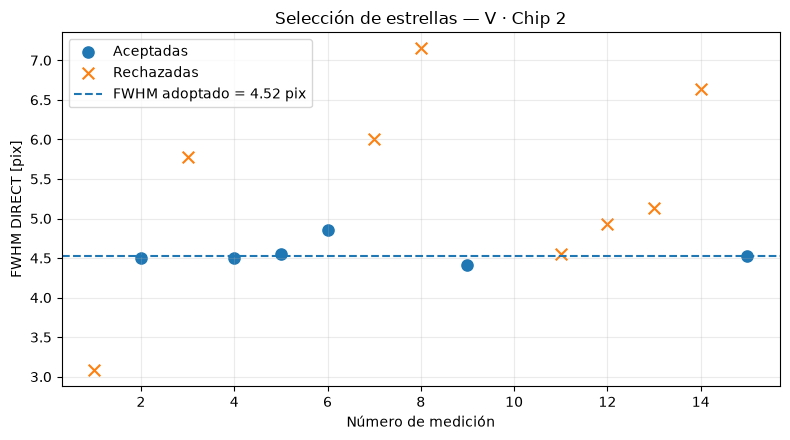

In [108]:

# Mediciones DIRECT de IRAF para V · Chip 2
fwhm_chip2 = pd.DataFrame({
    "medicion": np.arange(1, 16),
    "fwhm_direct": [
        3.08, 4.50, 5.78, 4.50, 4.55,
        4.85, 6.00, 7.15, 4.41, np.nan,
        4.55, 4.93, 5.13, 6.64, 4.53
    ]
})

# Selección supervisada
seleccion_chip2 = [2, 4, 5, 6, 9, 15]

fwhm_chip2["aceptada"] = (
    fwhm_chip2["medicion"].isin(seleccion_chip2)
)

valores = fwhm_chip2.loc[
    fwhm_chip2["aceptada"],
    "fwhm_direct"
].to_numpy()

# Función reutilizable del pipeline
res_fwhm = resumir_fwhm(valores)

# Parámetro adoptado con dos decimales
fwhm = round(res_fwhm["mediana"], 2)

r_ap = 3 * fwhm
r_sky_in = 5 * fwhm
r_sky_out = r_sky_in + 15

print()
print("Parámetros adoptados para Chip 2")
print(f"FWHM       = {fwhm:.2f} pix")
print(f"r_ap       = {r_ap:.2f} pix")
print(f"r_sky_in   = {r_sky_in:.2f} pix")
print(f"r_sky_out  = {r_sky_out:.2f} pix")

# Gráfica
aceptadas = fwhm_chip2[fwhm_chip2["aceptada"]]
rechazadas = fwhm_chip2[~fwhm_chip2["aceptada"]]

plt.figure(figsize=(8, 4.5))

plt.scatter(
    aceptadas["medicion"],
    aceptadas["fwhm_direct"],
    label="Aceptadas",
    s=65
)

plt.scatter(
    rechazadas["medicion"],
    rechazadas["fwhm_direct"],
    marker="x",
    label="Rechazadas",
    s=70
)

plt.axhline(
    fwhm,
    linestyle="--",
    label=f"FWHM adoptado = {fwhm:.2f} pix"
)

plt.xlabel("Número de medición")
plt.ylabel("FWHM DIRECT [pix]")
plt.title("Selección de estrellas — V · Chip 2")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**### Determinación del ruido del cielo para V · Chip 2**

Se seleccionaron visualmente \(22\) regiones de cielo de \(15\times15\) píxeles, utilizando `imexamine` de IRAF.

Cada región contiene:

$$
N_{\mathrm{pix}}=225.
$$

Para caracterizar la dispersión del fondo se utilizó la desviación estándar de cada región y se aplicó el criterio superior de Tukey:

$$
L=Q_3+1.5\,IQR.
$$

Los cuartiles obtenidos fueron:

$$
Q_1=3.34225\ \mathrm{ADU}
$$

$$
Q_3=4.24650\ \mathrm{ADU}.
$$

Por tanto:

$$
IQR=0.90425\ \mathrm{ADU}.
$$

El límite superior fue:

$$
L=5.602875\ \mathrm{ADU}.
$$

Ninguna de las 22 regiones superó este límite.

La mediana de las dispersiones fue:

$$
\sigma_{\mathrm{sky,med}}=3.6185\ \mathrm{ADU}.
$$

Para el procesamiento se adopta provisionalmente:

$$
\boxed{\sigma_{\mathrm{sky}}=3.62\ \mathrm{ADU}}
$$

Este valor será utilizado como parámetro de ruido de fondo en las pruebas de detección mediante `DAOFIND`, una vez verificada visualmente la ausencia de contaminación en las regiones seleccionadas.

Q1                 = 3.3422 ADU
Q3                 = 4.2465 ADU
IQR                = 0.9043 ADU
Límite Tukey       = 5.6029 ADU
Cajas aceptadas    = 22
Cajas rechazadas   = 0
Sigma sky adoptado = 3.6185 ADU
Mediana del cielo  = -0.2709 ADU


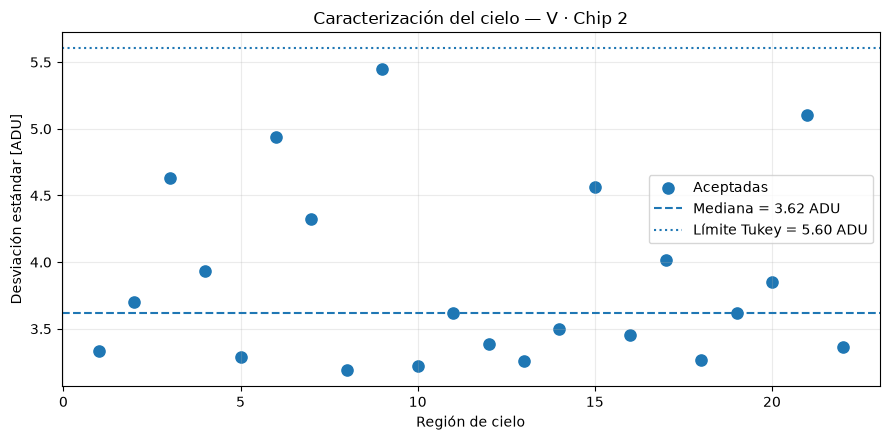

Sigma de cielo adoptada: 3.62 ADU


In [109]:
# Primeras 7 mediciones
sigmas_1 = [
    3.334, 3.699, 4.628, 3.931,
    3.291, 4.938, 4.323
]

medianas_1 = [
    -0.9401, -0.4355, -0.5113, -0.6402,
    -0.2368, -0.7196, 0.4283
]

# 15 mediciones adicionales
sigmas_2 = [
    3.188, 5.451, 3.223, 3.617, 3.389,
    3.262, 3.498, 4.562, 3.457, 4.017,
    3.269, 3.620, 3.848, 5.103, 3.367
]

medianas_2 = [
    -0.3049, -0.5989, -0.6700, -0.6747,
    0.5994, -0.3600, 1.3240, 0.5278,
    0.9748, -0.6367, 0.07013, -0.06157,
    0.2769, 0.1574, -0.07761
]

# Unir mediciones
sigma_cajas = np.array(sigmas_1 + sigmas_2)
mediana_cajas = np.array(medianas_1 + medianas_2)

# Función del pipeline
res_sky = resumir_cielo(
    sigma_cajas,
    medianas=mediana_cajas
)

sigma_sky = round(res_sky["sigma_sky"], 2)

# Guardar tabla de mediciones
tabla_sky = pd.DataFrame({
    "region": np.arange(1, len(sigma_cajas) + 1),
    "mediana_ADU": mediana_cajas,
    "sigma_ADU": sigma_cajas
})

tabla_sky["aceptada"] = (
    tabla_sky["sigma_ADU"] <= res_sky["limite"]
)

# Gráfica
plt.figure(figsize=(9, 4.5))

plt.scatter(
    tabla_sky.loc[tabla_sky["aceptada"], "region"],
    tabla_sky.loc[tabla_sky["aceptada"], "sigma_ADU"],
    label="Aceptadas",
    s=65
)

plt.axhline(
    sigma_sky,
    linestyle="--",
    label=f"Mediana = {sigma_sky:.2f} ADU"
)

plt.axhline(
    res_sky["limite"],
    linestyle=":",
    label=f"Límite Tukey = {res_sky['limite']:.2f} ADU"
)

plt.xlabel("Región de cielo")
plt.ylabel("Desviación estándar [ADU]")
plt.title("Caracterización del cielo — V · Chip 2")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Sigma de cielo adoptada: {sigma_sky:.2f} ADU")

Script creado:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_daofind.cl

Ejecutar dentro de IRAF:
cl < /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_daofind.cl


,threshold,detecciones
0,2.0,63288
1,2.5,31818
2,3.0,16306
3,3.5,9685
4,4.0,6272
5,5.0,2736
6,6.0,1197


ln(N) = 0.08975499 x² -1.68789947 x +14.02764389
R² = 0.99836083
Threshold calculado = 3.8321


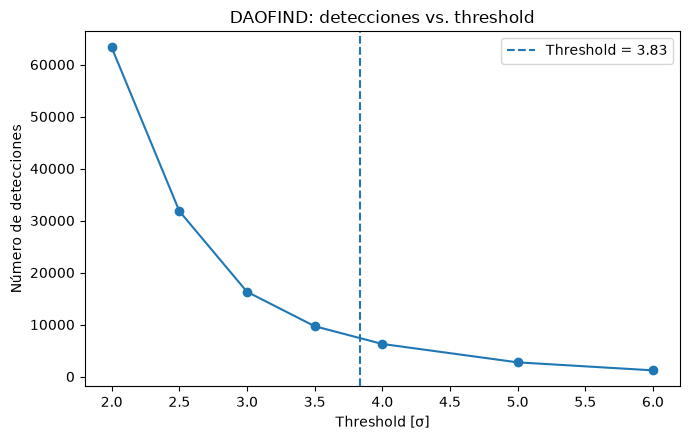

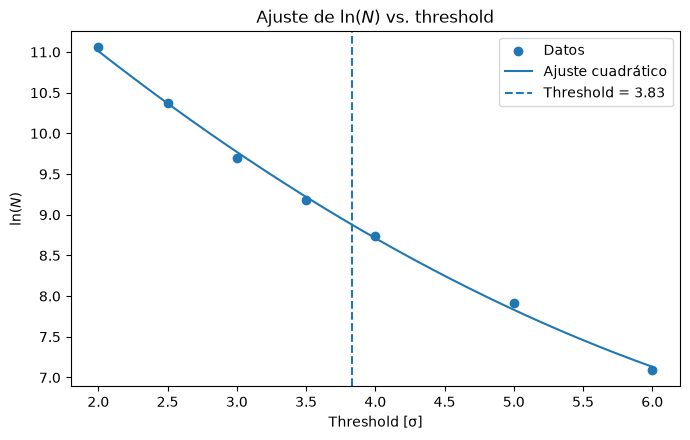

In [110]:
CHIP = 2
FILTRO = "V"

fwhm = 4.52
sigma_sky = 3.62

resultado_threshold = etapa_threshold(
    chip=CHIP,
    filtro=FILTRO,
    fwhm=fwhm,
    sigma_sky=sigma_sky
)

In [111]:
# Threshold definitivo para V · Chip 2

threshold_calculado = resultado_threshold["threshold"]

# Adoptamos dos decimales, como en Chip 1
threshold = round(threshold_calculado, 2)

print(f"Threshold calculado = {threshold_calculado:.4f}")
print(f"Threshold adoptado  = {threshold:.2f}")

Threshold calculado = 3.8321
Threshold adoptado  = 3.83


In [112]:
script_final, catalogo_final = generar_script_daofind_final(
    chip=2,
    filtro="V",
    fwhm=4.52,
    sigma_sky=3.62,
    threshold=threshold
)

print("Script:", script_final)
print("Catálogo de salida:", catalogo_final)

Script DAOFIND final:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_daofind_final.cl

Ejecutar en IRAF:
cl < /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_daofind_final.cl
Script: /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_daofind_final.cl
Catálogo de salida: /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_final.coo


In [113]:
# =====================================================
# V · CHIP 2 — LIMPIEZA GEOMÉTRICA AUTOMÁTICA
# =====================================================

CHIP = 2
FILTRO = "V"

fwhm = 4.52
sigma_sky = 3.62
threshold = 3.83

rutas = rutas_chip(CHIP, FILTRO)

catalogo_final = (
    rutas["carpeta"] / "V_chip2_final.coo"
)

# Contar detecciones definitivas
n_daofind = contar_catalogo_iraf(catalogo_final)

print("Detecciones DAOFIND:", n_daofind)

# Limpieza geométrica automática
resultado_geo = preparar_phot_fijo(
    chip=CHIP,
    filtro=FILTRO,
    fwhm=fwhm
)

Detecciones DAOFIND: 7291
DAOFIND inicial      : 7291
Apertura válida      : 5034
Anillo completo válido: 3535

Archivo PHOT-ready:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_phot_ready.xy


In [114]:
# Generar script IRAF de fotometría fija

script_phot, archivo_phot = generar_script_phot_fijo(
    chip=CHIP,
    filtro=FILTRO,
    fwhm=fwhm,
    sigma_sky=sigma_sky
)

print("Script generado:", script_phot)
print("Resultado esperado:", archivo_phot)

Script PHOT fijo:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_phot_fijo.cl

Ejecutar en IRAF:
cl < /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_phot_fijo.cl
Script generado: /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_phot_fijo.cl
Resultado esperado: /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_fixed.dat


In [115]:
# Leer fotometría fija
df_chip2 = cargar_phot(archivo_phot)

# Seleccionar fotometría válida
validas_chip2, calidad_chip2 = seleccionar_calidad(
    df_chip2,
    merr_max=0.20
)

print("===== V · CHIP 2 =====")
print("DAOFIND inicial :", n_daofind)
print("PHOT total      :", len(df_chip2))
print("PHOT válidas    :", len(validas_chip2))
print("MERR <= 0.20    :", len(calidad_chip2))

print()
print("Estadísticas de MERR:")
print(validas_chip2["merr"].describe())

===== V · CHIP 2 =====
DAOFIND inicial : 7291
PHOT total      : 3535
PHOT válidas    : 2311
MERR <= 0.20    : 549

Estadísticas de MERR:
count    2311.000000
mean        2.000466
std         6.075865
min         0.001000
25%         0.233000
50%         0.687000
75%         1.483000
max        85.129000
Name: merr, dtype: float64


In [116]:
carpeta = BASE / "chips/chip2"

archivo_coords = carpeta / "V_chip2_phot_ready.xy"
archivo_phot = carpeta / "V_chip2_fixed.dat"

n_coords = contar_catalogo_iraf(archivo_coords)
n_phot = contar_catalogo_iraf(archivo_phot)

print("Coordenadas enviadas a PHOT:", n_coords)
print("Filas fotométricas:", n_phot)
print("Coinciden:", n_coords == n_phot)

Coordenadas enviadas a PHOT: 3535
Filas fotométricas: 3535
Coinciden: True


In [117]:
df_chip2 = cargar_phot(archivo_phot)

validas_chip2, calidad_chip2 = seleccionar_calidad(
    df_chip2,
    merr_max=0.20
)

print("PHOT total:", len(df_chip2))
print("MAG y MERR válidas:", len(validas_chip2))
print("MERR <= 0.20:", len(calidad_chip2))

PHOT total: 3535
MAG y MERR válidas: 2311
MERR <= 0.20: 549


In [118]:
# ==============================================
# V · CHIP 2 — ANÁLISIS POST-PHOT AUTOMÁTICO
# ==============================================

resultado_post = analizar_post_phot(
    chip=2,
    filtro="V",
    fwhm=4.52,
    sigma_sky=3.62,
    merr_max=0.20
)

# Mostrar resumen
resumen_chip2 = resultado_post["resumen"]

display(pd.DataFrame([resumen_chip2]).T)

# Mostrar grupos de anillos seleccionados
display(resultado_post["tabla_grupos"])

print("\nScript IRAF adaptativo:")
print(resultado_post["script_adapt"])

Máx. distancia match propio = 0.000000
Mediana distancia vecino    = 31.8755 pix
Aisladas                    = 387
Rechazadas por vecino       = 162
Total analizadas = 387
f_lim             = 0.017964 (1.80%)
Cielo limpio      = 321
Contaminadas      = 66
   r_in  r_out    n
0  22.6   37.6  321
1  27.6   42.6   17
2  32.6   47.6    5
3  37.6   52.6   12
4  42.6   57.6   11
Script creado:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_phot_adaptativo.cl

Ejecutar dentro de IRAF:
cl < /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_phot_adaptativo.cl

===== RESUMEN PRELIMINAR =====
chip: 2
filtro: V
fwhm: 4.52
sigma_sky: 3.62
N_phot_total: 3535
N_phot_validas: 2311
N_MERR: 549
N_aisladas: 387
f_lim: 0.01796442101848754
N_fijo_limpio: 321
N_fijo_contaminado: 66
N_adapt_aceptadas: 366
N_recuperadas: 45
N_sin_solucion: 21
tasa_recuperacion: 68.18181818181819


,0
chip,2
filtro,V
fwhm,4.52
sigma_sky,3.62
N_phot_total,3535
N_phot_validas,2311
N_MERR,549
N_aisladas,387
f_lim,0.017964
N_fijo_limpio,321


,r_in,r_out,n,coords,tag
0,22.6,37.6,321,/Users/santiagoserranoperico/Desktop/Universid...,r22_60_37_60
1,27.6,42.6,17,/Users/santiagoserranoperico/Desktop/Universid...,r27_60_42_60
2,32.6,47.6,5,/Users/santiagoserranoperico/Desktop/Universid...,r32_60_47_60
3,37.6,52.6,12,/Users/santiagoserranoperico/Desktop/Universid...,r37_60_52_60
4,42.6,57.6,11,/Users/santiagoserranoperico/Desktop/Universid...,r42_60_57_60



Script IRAF adaptativo:
/Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_phot_adaptativo.cl


In [119]:
script_adapt = resultado_post["script_adapt"]

print("Script:", script_adapt)
print(
    "Salto de línea final:",
    script_adapt.read_bytes().endswith(b"\n")
)

Script: /Users/santiagoserranoperico/Desktop/Universidad/tesis/dataSextansA/chips/chip2/V_chip2_phot_adaptativo.cl
Salto de línea final: True


In [120]:
# Comprobar los resultados de PHOT adaptativo

grupos = resultado_post["tabla_grupos"]
carpeta = rutas_chip(2, "V")["carpeta"]

total_obtenido = 0

for _, grupo in grupos.iterrows():
    archivo = carpeta / f"V_chip2_adapt_{grupo['tag']}.dat"

    if archivo.exists():
        n = contar_catalogo_iraf(archivo)
        total_obtenido += n
        print(
            f"Anillo {grupo['r_in']:.2f}–{grupo['r_out']:.2f}: "
            f"esperadas={grupo['n']}, obtenidas={n}"
        )
    else:
        print(f"FALTA: {archivo.name}")

print("\nTotal esperado:", 366)
print("Total obtenido:", total_obtenido)
print("Coinciden:", total_obtenido == 366)

Anillo 22.60–37.60: esperadas=321, obtenidas=321
Anillo 27.60–42.60: esperadas=17, obtenidas=17
Anillo 32.60–47.60: esperadas=5, obtenidas=5
Anillo 37.60–52.60: esperadas=12, obtenidas=12
Anillo 42.60–57.60: esperadas=11, obtenidas=11

Total esperado: 366
Total obtenido: 366
Coinciden: True


In [121]:
# ====================================================
# V · CHIP 2 — COMPARACIÓN FIJO VS. ADAPTATIVO
# ====================================================

resultado_comp = comparar_fijo_adaptativo(
    chip=2,
    filtro="V",
    r_sky_in=22.60,
    df_anillos=resultado_post["df_anillos"]
)

# Resultados generales
display(
    pd.DataFrame.from_dict(
        resultado_comp["resumen"],
        orient="index",
        columns=["Valor"]
    )
)

# Verificación del grupo de control
control = resultado_comp["control"]
movidas = resultado_comp["movidas"]

print("\n===== VALIDACIÓN =====")
print("Estrellas de control:", len(control))
print("Estrellas desplazadas con fotometría válida:", len(movidas))

for variable in ["mag", "merr", "msky", "stdev", "flux"]:
    diferencia = (
        control[f"{variable}_adapt"]
        - control[f"{variable}_fixed"]
    )
    print(
        f"Máx |Δ{variable.upper()}| control:",
        np.nanmax(np.abs(diferencia))
    )

print(
    "Máxima distancia de asociación:",
    resultado_comp["comparacion"]["dist_match"].max(),
    "pix"
)

===== ASOCIACIÓN DE FUENTES =====
Matches: 366
Máx. distancia match: 0.000000 pix

===== GRUPO DE CONTROL =====
Estrellas de control: 321
Máx |ΔMAG|: 0.0
Máx |ΔMERR|: 0.0
Máx |ΔMSKY|: 0.0
Máx |ΔSTDEV|: 0.0
Máx |ΔFLUX|: 0.0

===== ANILLOS DESPLAZADOS =====
Total desplazadas: 45
Fotometría válida en ambas: 45

===== SELECCIÓN ADAPTATIVA =====
Estrellas aceptadas: 366

===== COMPARACIÓN FOTOMÉTRICA =====
N_control: 321
N_movidas_total: 45
N_movidas_validas: 45
med_delta_msky: -0.08979019999999999
med_delta_stdev: -0.10185999999999984
med_delta_mag: -0.009999999999999787
med_abs_delta_mag: 0.019000000000000128
med_merr_fixed: 0.035
med_merr_adapt: 0.032
pct_merr_mejora: 62.22222222222222
med_snr_fixed: 31.02
med_snr_adapt: 33.928125
med_flux_ratio: 1.009239615263743
med_fout_inicial: 0.030356512530885987
med_fout_final: 0.011986
med_delta_fout: -0.01985793088857546
pct_fout_reduce: 100.0


,Valor
N_control,321.000000
N_movidas_total,45.000000
N_movidas_validas,45.000000
med_delta_msky,-0.089790
med_delta_stdev,-0.101860
med_delta_mag,-0.010000
med_abs_delta_mag,0.019000
med_merr_fixed,0.035000
med_merr_adapt,0.032000
pct_merr_mejora,62.222222



===== VALIDACIÓN =====
Estrellas de control: 321
Estrellas desplazadas con fotometría válida: 45
Máx |ΔMAG| control: 0.0
Máx |ΔMERR| control: 0.0
Máx |ΔMSKY| control: 0.0
Máx |ΔSTDEV| control: 0.0
Máx |ΔFLUX| control: 0.0
Máxima distancia de asociación: 0.0 pix


**### Resultados de la fotometría adaptativa — V · Chip 2**

Se ejecutó la fotometría adaptativa sobre 366 fuentes, distribuidas
en cinco grupos según el radio interior del anillo de cielo.

De estas fuentes, 321 conservaron el anillo original y constituyeron
el grupo de control. Las 45 restantes utilizaron un anillo desplazado.

**Validación del grupo de control**

Las 321 fuentes del grupo de control presentaron diferencias nulas
en magnitud, error fotométrico, nivel de cielo, dispersión del cielo
y flujo.

La distancia máxima de asociación entre los catálogos fue de
0 píxeles, lo que confirma la correspondencia de las fuentes.

**Recuperación de fuentes**

De 66 fuentes cuyos anillos iniciales fueron clasificados como
contaminados, 45 encontraron un anillo alternativo aceptable.

La tasa de recuperación fue:

$$
R = \frac{45}{66}\times100
  = 68.18\%.
$$

Las 21 fuentes restantes no encontraron un anillo aceptable
dentro de las cinco alternativas evaluadas.

**Comparación fotométrica**

Para las 45 fuentes recuperadas se obtuvieron las siguientes
medianas de las diferencias entre la fotometría adaptativa y fija:

$$
\widetilde{\Delta MSKY}=-0.08979\ \mathrm{ADU}
$$

$$
\widetilde{\Delta STDEV}=-0.10186\ \mathrm{ADU}
$$

$$
\widetilde{\Delta MAG}=-0.010\ \mathrm{mag}
$$

$$
\mathrm{mediana}(|\Delta MAG|)=0.019\ \mathrm{mag}
$$

La mediana del error fotométrico disminuyó de 0.035 mag
a 0.032 mag. En 28 de las 45 fuentes (62.22 %) se observó
una reducción individual de MERR.

La mediana de la relación señal-ruido pasó de 31.020 a 33.928,
mientras que la mediana del cociente de flujos fue 1.00924.

**Contaminación del cielo**

La mediana del indicador de contaminación pasó de 3.04 %
en los anillos iniciales a 1.20 % en los seleccionados.

La mediana de las diferencias individuales fue de -1.99
puntos porcentuales. Las 45 fuentes presentaron una reducción
del indicador de contaminación.

**Interpretación**

Los resultados muestran que la selección adaptativa puede
identificar anillos alternativos que satisfacen el criterio
de contaminación establecido y modificar favorablemente
algunas métricas fotométricas internas.

No obstante, la disminución del indicador de contaminación
es consecuencia, en parte, del criterio utilizado para
seleccionar los anillos. Los resultados no constituyen por
sí solos una demostración de mayor exactitud fotométrica
absoluta.

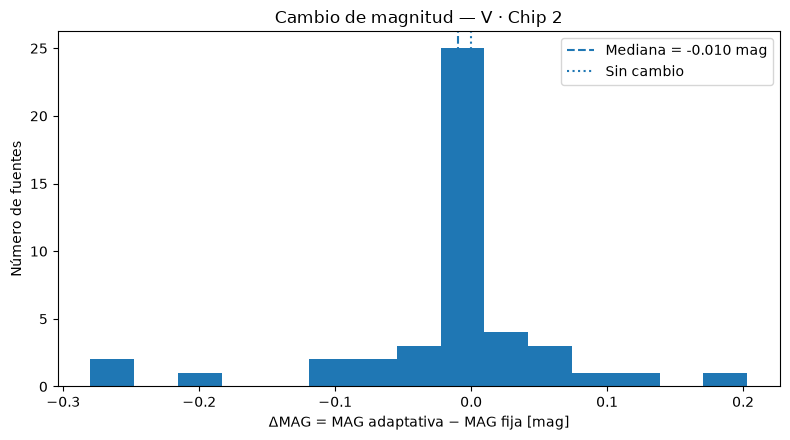

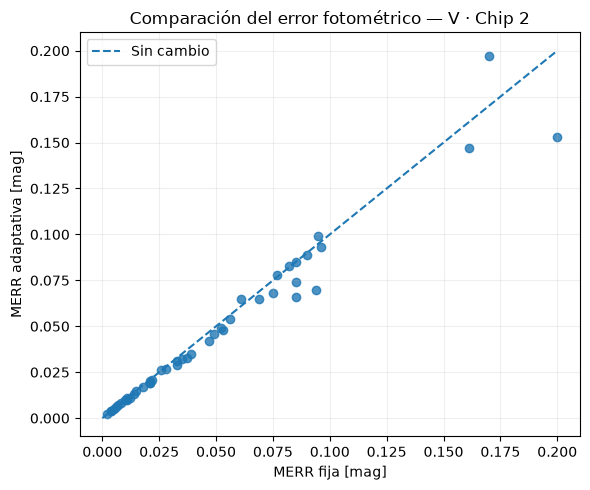

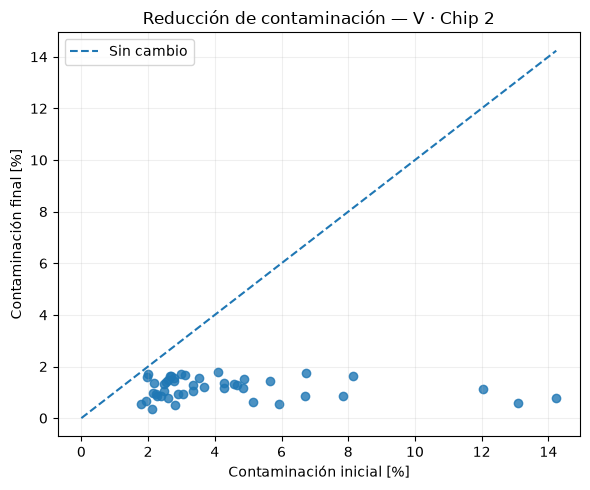

Fuentes comparadas: 45
Fuentes con f_out comparado: 45


In [122]:
movidas = resultado_comp["movidas"].copy()
fout = resultado_comp["fout"].copy()

# Gráfica 1: cambios de magnitud
plt.figure(figsize=(8, 4.5))

plt.hist(movidas["delta_mag"].dropna(), bins=15)

plt.axvline(
    np.median(movidas["delta_mag"]),
    linestyle="--",
    label=f"Mediana = {np.median(movidas['delta_mag']):.3f} mag"
)

plt.axvline(0, linestyle=":", label="Sin cambio")
plt.xlabel("ΔMAG = MAG adaptativa − MAG fija [mag]")
plt.ylabel("Número de fuentes")
plt.title("Cambio de magnitud — V · Chip 2")
plt.legend()
plt.tight_layout()
plt.show()


# Gráfica 2: error fotométrico
plt.figure(figsize=(6, 5))

plt.scatter(
    movidas["merr_fixed"],
    movidas["merr_adapt"],
    alpha=0.8
)

limite = max(
    movidas["merr_fixed"].max(),
    movidas["merr_adapt"].max()
)

plt.plot(
    [0, limite], [0, limite],
    linestyle="--", label="Sin cambio"
)

plt.xlabel("MERR fija [mag]")
plt.ylabel("MERR adaptativa [mag]")
plt.title("Comparación del error fotométrico — V · Chip 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# Gráfica 3: contaminación inicial vs. final
plt.figure(figsize=(6, 5))

x = 100 * fout["f_out_inicial"]
y = 100 * fout["f_out_final"]

plt.scatter(x, y, alpha=0.8)

limite = max(x.max(), y.max())

plt.plot(
    [0, limite], [0, limite],
    linestyle="--", label="Sin cambio"
)

plt.xlabel("Contaminación inicial [%]")
plt.ylabel("Contaminación final [%]")
plt.title("Reducción de contaminación — V · Chip 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Fuentes comparadas:", len(movidas))
print("Fuentes con f_out comparado:", len(fout))